# PP14 — Image Generation with GANs
**Gudsky Research Foundation · Research Intake 2026 · Day 34 graded assignment**

This notebook implements and compares the three approaches the brief requires, **each trained from scratch in this notebook**:

| | Approach | Model | Task |
|---|---|---|---|
| **A** | vanilla / DCGAN (§5) | unconditional generator + discriminator | noise → clothing image |
| **B** | class-conditioned GAN (§6) | label fed to both networks | noise + class → clothing image of that class |
| **C** | image-to-image translation (§7) | pix2pix (U-Net generator, PatchGAN discriminator) | edge map → clothing image |

## How the brief's rubric maps onto this notebook
| Brief requirement | Where |
|---|---|
| Three genuinely trained pipelines with documented configs | Parts 2–4 (config table printed before each training run) |
| FID where practical, **same protocol for all three** (§9.5) | Part 1 (metric toolkit, sanity-checked) and Part 6 |
| Stability observations against §4's failure modes | Part 5 (diagnostics and two deliberate ablations) |
| Comparison table/plot: quality, stability, controllability, compute | Part 6 |
| Recommendation tied to §5–7 trade-offs | Part 7 |
| Documented code, README to reproduce | Part 8 |

## Scope decisions (stated up front)
* **Dataset: Fashion-MNIST, 10 classes, padded from 28×28 to 32×32.** The brief asks for a compact, low-resolution dataset (§B); this one is hosted on GitHub, so it also downloads in restricted environments. Approaches A and B use it directly. Approach C needs *paired* data, so I **construct** the pairs: input = Sobel edge map of each image, target = the image itself (the same construction as the classic edges→shoes task, with edges computed rather than hand-drawn). This is a synthetic pairing, not a natural paired dataset, and conclusions about C hold for that kind of task.
* **Compute: this notebook was run on a 2-core CPU, no GPU.** Models are therefore small (generator width 16, i.e. a quarter of the usual DCGAN width) and trained for 3000 iterations (about 3 epochs) — far fewer than a published GAN. Every number below is from *this* budget (the brief's §11.2 warns against comparing with published benchmarks, and I do not).
* Every measured quantity is tagged `[measured]`; anything chosen by me rather than measured is tagged `[assumed]`.

In [1]:
from __future__ import annotations

import gzip
import json
import math
import os
import shutil
import ssl
import subprocess
import sys
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from skimage.metrics import structural_similarity

try:
    import pytorch_fid  # noqa: F401
except ImportError:  # Colab does not ship it
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pytorch-fid", "--no-deps"])

from pytorch_fid.inception import InceptionV3

SEED = 17
QUICK = os.environ.get("PP14_QUICK", "0") == "1"  # smoke-test mode: tiny budgets, same code path
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path("pp14_data")
OUT_DIR = Path("pp14_outputs")
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": False})

# Training budgets: identical iteration count and batch size for A, B and C (matched conditions, §9.5).
CFG = dict(
    iters=3000 if not QUICK else 60,        # generator updates per approach
    batch=64,
    lr=2e-4, beta1=0.5,                      # DCGAN paper defaults
    eval_every=500 if not QUICK else 30,    # checkpoint: sample grid + cheap metrics
    n_eval=5000 if not QUICK else 300,       # images per set for the final evaluation (classifier-feature metrics)
    n_fid=1000 if not QUICK else 100,        # images per set for Inception FID (8 img/s on a 2-core CPU, so kept small)
    n_monitor=2000 if not QUICK else 200,    # images per set for in-training monitoring
    abl_iters=1000 if not QUICK else 30,     # length of each deliberate-failure ablation
    nz=100, ng=16, ndf_p2p=32,
)


def seed_all(seed: int = SEED) -> None:
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


seed_all()
torch.set_float32_matmul_precision("high")
print(f"torch {torch.__version__} | device {DEVICE} | threads {torch.get_num_threads()} | QUICK={QUICK}")
print("config:", json.dumps(CFG))

torch 2.15.0+cu132 | device cpu | threads 2 | QUICK=False
config: {"iters": 3000, "batch": 64, "lr": 0.0002, "beta1": 0.5, "eval_every": 500, "n_eval": 5000, "n_fid": 1000, "n_monitor": 2000, "abl_iters": 1000, "nz": 100, "ng": 16, "ndf_p2p": 32}


## Data
Fashion-MNIST (Xiao, Rasul, Vollgraf 2017; 60 000 train / 10 000 test, 10 classes) is downloaded from its GitHub repository. The Inception weights used for FID are the ones from the `pytorch-fid` project (the TensorFlow-FID-compatible port), also from GitHub. If a download fails the cell says so rather than continuing silently.

data ready in 2.1 s: train (60000, 1, 32, 32), test (10000, 1, 32, 32), range [-1, 1]


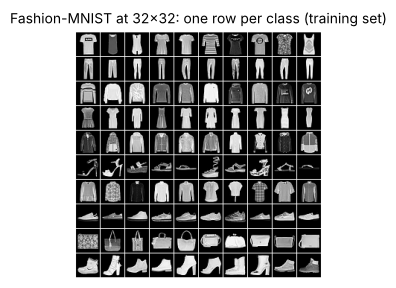

In [2]:
FMNIST_URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
FID_URL = "https://github.com/mseitzer/pytorch-fid/releases/download/fid_weights/pt_inception-2015-12-05-6726825d.pth"
FID_FILE = "pt_inception-2015-12-05-6726825d.pth"
CLASS_NAMES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Boot"]


def download(url: str, dest: Path) -> None:
    if dest.exists() and dest.stat().st_size > 0:
        return
    try:
        resp = urllib.request.urlopen(url, timeout=120)
    except (ssl.SSLError, urllib.error.URLError):
        import certifi  # fallback for machines with a broken CA bundle

        resp = urllib.request.urlopen(url, timeout=120, context=ssl.create_default_context(cafile=certifi.where()))
    with resp, open(dest, "wb") as fh:
        shutil.copyfileobj(resp, fh)


def read_idx(path: Path) -> np.ndarray:
    with gzip.open(path, "rb") as fh:
        raw = fh.read()
    ndim = raw[3]
    shape = tuple(int.from_bytes(raw[4 + 4 * i: 8 + 4 * i], "big") for i in range(ndim))
    return np.frombuffer(raw, dtype=np.uint8, offset=4 + 4 * ndim).reshape(shape)


t0 = time.time()
for f in ["train-images-idx3-ubyte", "train-labels-idx1-ubyte", "t10k-images-idx3-ubyte", "t10k-labels-idx1-ubyte"]:
    download(FMNIST_URL + f + ".gz", DATA_DIR / f"{f}.gz")
hub_ckpt = Path(torch.hub.get_dir()) / "checkpoints"
hub_ckpt.mkdir(parents=True, exist_ok=True)
download(FID_URL, hub_ckpt / FID_FILE)  # InceptionV3(use_fid_inception=True) finds it here and will not re-download

x_tr = read_idx(DATA_DIR / "train-images-idx3-ubyte.gz")
y_tr = read_idx(DATA_DIR / "train-labels-idx1-ubyte.gz").astype(np.int64)
x_te = read_idx(DATA_DIR / "t10k-images-idx3-ubyte.gz")
y_te = read_idx(DATA_DIR / "t10k-labels-idx1-ubyte.gz").astype(np.int64)
assert x_tr.shape == (60000, 28, 28) and x_te.shape == (10000, 28, 28), (x_tr.shape, x_te.shape)
assert np.bincount(y_tr).tolist() == [6000] * 10, "Fashion-MNIST train should be exactly balanced"


def to_tensor32(x_u8: np.ndarray) -> torch.Tensor:
    """uint8 (N,28,28) -> float (N,1,32,32) in [-1, 1]; 2 px of background padding so strided convs give 4x4 / 2x2."""
    t = torch.from_numpy(x_u8.copy()).float().div(127.5).sub(1.0).unsqueeze(1)
    return F.pad(t, (2, 2, 2, 2), value=-1.0)


X_TR, Y_TR = to_tensor32(x_tr).to(DEVICE), torch.from_numpy(y_tr).to(DEVICE)
X_TE, Y_TE = to_tensor32(x_te).to(DEVICE), torch.from_numpy(y_te).to(DEVICE)
print(f"data ready in {time.time() - t0:.1f} s: train {tuple(X_TR.shape)}, test {tuple(X_TE.shape)}, range [{X_TR.min():.0f}, {X_TR.max():.0f}]")


def show_grid(imgs: torch.Tensor, nrow: int = 10, ax=None, title: str | None = None) -> None:
    """imgs in [-1, 1], shape (N,1,H,W)."""
    from torchvision.utils import make_grid

    g = make_grid(imgs.detach().cpu().clamp(-1, 1).add(1).div(2), nrow=nrow, padding=1, pad_value=1.0)
    ax = ax or plt.gca()
    ax.imshow(g[0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=10)


fig, ax = plt.subplots(figsize=(7, 3.2))
show_grid(torch.cat([X_TR[Y_TR == c][:10] for c in range(10)]), 10, ax, "Fashion-MNIST at 32x32: one row per class (training set)")
plt.show()

# Part 1 — Evaluation toolkit (built and sanity-checked *before* any GAN is trained)
§9.5 requires one evaluation protocol applied identically to all three approaches. Generative models have no ground truth to compare against (§1), so the toolkit is the part most worth validating.

| Metric | What it measures | Reference |
|---|---|---|
| **FID** (Inception pool3, 2048-d) | distance between real and generated feature distributions (Fréchet distance of two Gaussians) | Heusel et al., NeurIPS 2017 |
| **FD-cls** | the same Fréchet distance, but in the 128-d feature space of a Fashion-MNIST classifier I train here. Cheap enough to track *during* training. It is domain-specific and **not comparable to Inception FID** | my own variant `[assumed]` |
| **Precision / Recall** (k = 3) | precision: fraction of generated samples inside the real manifold (quality); recall: fraction of real samples inside the generated manifold (coverage / diversity) | Kynkäänniemi et al., NeurIPS 2019 |
| **Class histogram** | the trained classifier labels each generated image; a collapsed generator shows an uneven histogram (§4.1) | — |
| **Conditional accuracy** | for B and C: does the classifier recover the requested class? (correctness relative to the condition, §9.5) | — |

**Protocol constants (identical for every approach):** reference set = first 5000 images of the Fashion-MNIST *test* set (never seen in training); each generated set has the same size; the same Inception network and the same code.
**Inception is slow on a CPU (≈ 8 images/s here), so FID uses the first `n_fid` = 1000 images of every set (reference included); the classifier-feature metrics use the full 5000.** FID is biased upward for small sample sets (§11.2), so absolute values are not comparable with published numbers; only the within-notebook comparison is meaningful, and the real-vs-real noise floor is printed next to it.

In [3]:
class FashionCNN(nn.Module):
    """Small classifier; its penultimate layer is the feature space for FD-cls and precision/recall."""

    def __init__(self) -> None:
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 16
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 8
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 4
        )
        self.fc = nn.Sequential(nn.Flatten(), nn.Linear(128 * 16, 128), nn.ReLU())
        self.head = nn.Linear(128, 10)

    def features(self, x: torch.Tensor) -> torch.Tensor:
        return self.fc(self.conv(x))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.head(self.features(x))


def train_classifier(epochs: int = 3) -> FashionCNN:
    seed_all()
    net = FashionCNN().to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), 1e-3)
    n = X_TR.shape[0]
    for ep in range(epochs):
        net.train()
        perm = torch.randperm(n, device=DEVICE)
        for i in range(0, n, 128):
            idx = perm[i:i + 128]
            loss = F.cross_entropy(net(X_TR[idx]), Y_TR[idx])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
    return net.eval()


@torch.no_grad()
def classify(net: FashionCNN, x: torch.Tensor, bs: int = 500) -> tuple[torch.Tensor, torch.Tensor]:
    """Returns (class probabilities, 128-d features) on CPU."""
    probs, feats = [], []
    for i in range(0, len(x), bs):
        f = net.features(x[i:i + bs].to(DEVICE))
        feats.append(f.cpu())
        probs.append(F.softmax(net.head(f), 1).cpu())
    return torch.cat(probs), torch.cat(feats)


t0 = time.time()
CLF = train_classifier()
_p, _ = classify(CLF, X_TE)
CLF_TEST_ACC = (_p.argmax(1) == Y_TE.cpu()).float().mean().item()
print(f"[measured] reference classifier: test accuracy {CLF_TEST_ACC:.4f} ({time.time() - t0:.0f} s). "
      "It is only a measuring instrument; it is never used to train a GAN.")

[measured] reference classifier: test accuracy 0.9025 (109 s). It is only a measuring instrument; it is never used to train a GAN.


In [4]:
def frechet_distance(f1: np.ndarray, f2: np.ndarray) -> float:
    """Fréchet distance between Gaussians fitted to two feature sets (rows = samples)."""
    f1, f2 = f1.astype(np.float64), f2.astype(np.float64)
    mu1, mu2 = f1.mean(0), f2.mean(0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    # tr(sqrt(S1 S2)) = sum of square roots of the eigenvalues of S1 S2 (same quantity as the reference FID code's
    # sqrtm-based trace, but ~6x faster for 2048-d features); tiny imaginary parts from round-off are dropped.
    eig = np.linalg.eigvals(s1.dot(s2))
    tr_covmean = float(np.sqrt(eig.astype(np.complex128)).real.sum())
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1) + np.trace(s2) - 2 * tr_covmean)


def precision_recall(real: torch.Tensor, fake: torch.Tensor, k: int = 3) -> tuple[float, float]:
    """k-NN manifold precision / recall (Kynkäänniemi et al. 2019)."""

    def radii(x: torch.Tensor) -> torch.Tensor:
        d = torch.cdist(x, x)
        return d.kthvalue(k + 1, dim=1).values  # k-th neighbour, skipping self at distance 0

    r_real, r_fake = radii(real), radii(fake)
    d_rf = torch.cdist(real, fake)  # (n_real, n_fake)
    precision = (d_rf <= r_real[:, None]).any(0).float().mean().item()  # fake inside some real ball
    recall = (d_rf <= r_fake[None, :]).any(1).float().mean().item()     # real inside some fake ball
    return precision, recall


INCEPTION = InceptionV3([InceptionV3.BLOCK_INDEX_BY_DIM[2048]], resize_input=True, normalize_input=True, use_fid_inception=True)
INCEPTION = INCEPTION.to(DEVICE).eval()


@torch.no_grad()
def inception_features(x: torch.Tensor, bs: int = 100) -> np.ndarray:
    """x in [-1,1], (N,1,32,32) -> (N,2048) pool3 features (grey replicated to 3 channels, resized to 299 inside the network)."""
    out = []
    for i in range(0, len(x), bs):
        b = x[i:i + bs].to(DEVICE).clamp(-1, 1).add(1).div(2).repeat(1, 3, 1, 1)
        out.append(INCEPTION(b)[0].squeeze(-1).squeeze(-1).cpu())
    return torch.cat(out).numpy()


class Evaluator:
    """One object, one protocol: every approach is scored through `score()`."""

    def __init__(self, n: int, n_fid: int) -> None:
        self.n = n
        self.n_fid = n_fid
        self.ref_img = X_TE[:n]
        self.ref_lbl = Y_TE[:n]
        t = time.time()
        self.ref_inc = inception_features(self.ref_img[:n_fid])
        self.inception_seconds = (time.time() - t) / n_fid
        _, self.ref_cls = classify(CLF, self.ref_img)
        self.ref_cls_np = self.ref_cls.numpy()

    def fd_cls(self, imgs: torch.Tensor) -> float:
        return frechet_distance(classify(CLF, imgs)[1].numpy(), self.ref_cls_np)

    def class_stats(self, imgs: torch.Tensor) -> dict:
        probs, _ = classify(CLF, imgs)
        hist = np.bincount(probs.argmax(1).numpy(), minlength=10) / len(imgs)
        ent = float(abs(-(hist[hist > 0] * np.log(hist[hist > 0])).sum() / math.log(10)))  # 1.0 = perfectly even
        return dict(class_hist=hist.round(4).tolist(), class_entropy=ent, min_class_share=float(hist.min()),
                    mean_confidence=float(probs.max(1).values.mean()))

    def score(self, imgs: torch.Tensor, requested: torch.Tensor | None = None, with_fid: bool = True) -> dict:
        probs, feats = classify(CLF, imgs)
        res = dict(n=len(imgs), fd_cls=frechet_distance(feats.numpy(), self.ref_cls_np), **self.class_stats(imgs))
        res["precision"], res["recall"] = precision_recall(self.ref_cls, feats)
        res["_cls_feats"] = feats.numpy()  # kept for bootstrap intervals; keys starting with "_" are not tabulated or saved
        if with_fid:
            res["fid"] = frechet_distance(inception_features(imgs[:self.n_fid]), self.ref_inc)
        if requested is not None:
            res["cond_accuracy"] = float((probs.argmax(1) == requested.cpu()).float().mean())
        return res


EVAL = Evaluator(CFG["n_eval"], CFG["n_fid"])
print(f"reference set: {EVAL.n} test images ({EVAL.n_fid} for Inception FID) | Inception speed on this machine: {1 / EVAL.inception_seconds:.0f} img/s")

reference set: 5000 test images (1000 for Inception FID) | Inception speed on this machine: 8 img/s


### Sanity checks of the metrics (before trusting them on GANs)
Four sets with known properties, scored with the exact same code:
* **real train images** — should score near the noise floor (same distribution, different images);
* **one class only** (5000 real images of a single class) — a *perfectly sharp but fully collapsed* generator: precision should stay high while recall and FID expose the missing diversity (§9.4);
* **blurred real images** — right content, wrong texture: FID should rise even though the class is recognisable;
* **Gaussian noise** — should be the worst on every metric.

In [5]:
g = torch.Generator().manual_seed(SEED)
n = CFG["n_eval"]
tr_idx = torch.randperm(60000, generator=g)[:n]
one_class = X_TR[Y_TR == 1][:n] if (Y_TR == 1).sum() >= n else X_TR[Y_TR == 1].repeat(math.ceil(n / 6000), 1, 1, 1)[:n]
blurred = F.avg_pool2d(F.pad(X_TR[tr_idx], (1, 1, 1, 1), mode="replicate"), 3, 1)
noise = torch.randn(n, 1, 32, 32, generator=g).clamp(-1, 1).to(DEVICE)
CHECKS = {
    "real train images (noise floor)": EVAL.score(X_TR[tr_idx]),
    "single class only (collapsed)": EVAL.score(one_class),
    "blurred real images": EVAL.score(blurred, with_fid=False),   # FD-cls only: Inception FID costs ~2 min per set on this CPU
    "Gaussian noise": EVAL.score(noise, with_fid=False),
}


def table(rows: list[list], header: list[str]) -> None:
    w = [max(len(str(r[i])) for r in [header] + rows) for i in range(len(header))]
    line = lambda r: "  ".join(str(c).ljust(w[i]) for i, c in enumerate(r))  # noqa: E731
    print(line(header))
    print("  ".join("-" * x for x in w))
    for r in rows:
        print(line(r))


table([[k, f"{v['fid']:.1f}" if "fid" in v else "-", f"{v['fd_cls']:.2f}", f"{v['precision']:.3f}", f"{v['recall']:.3f}", f"{v['class_entropy']:.3f}"]
       for k, v in CHECKS.items()], ["set (n=%d)" % n, "FID", "FD-cls", "precision", "recall", "class entropy"])
FID_FLOOR = CHECKS["real train images (noise floor)"]["fid"]
print(f"\n[measured] FID noise floor with n_fid={EVAL.n_fid}: {FID_FLOOR:.1f}. A GAN cannot meaningfully beat this number; "
      "differences much smaller than it are not trustworthy. ('-' = Inception FID not computed for that set.)")

set (n=5000)                     FID    FD-cls   precision  recall  class entropy
-------------------------------  -----  -------  ---------  ------  -------------
real train images (noise floor)  22.1   0.48     0.900      0.895   0.999        
single class only (collapsed)    125.1  1230.07  0.904      0.128   0.039        
blurred real images              -      99.09    0.875      0.094   0.996        
Gaussian noise                   -      764.69   0.030      0.000   0.329        

[measured] FID noise floor with n_fid=1000: 22.1. A GAN cannot meaningfully beat this number; differences much smaller than it are not trustworthy. ('-' = Inception FID not computed for that set.)


# Part 2 — Approach A: vanilla / DCGAN (§5)
**Architecture follows the DCGAN guidelines (Radford, Metz, Chintala 2016):** strided convolutions instead of pooling, batch-norm in both networks (not on the generator output or discriminator input), no fully-connected layers, ReLU in the generator with a `tanh` output, LeakyReLU(0.2) in the discriminator, weights initialised from N(0, 0.02).
**Loss:** the *non-saturating* generator loss of §3.4 — the generator maximises log D(G(z)) instead of minimising log(1 − D(G(z))). In code that is `BCE(D(G(z)), target=1)`. Part 5 *measures* what goes wrong with the original minimax form instead of just asserting it.
One shared training function is used for all GAN runs (A, B and the ablations), so the approaches differ only in what the brief says they should differ in.

In [6]:
def init_weights(m: nn.Module) -> None:
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)


class DCGenerator(nn.Module):
    """z (+ optional one-hot class) -> 1x32x32 image in [-1, 1]. Same module serves A (n_cls=0) and B (n_cls=10)."""

    def __init__(self, nz: int = 100, ng: int = 32, n_cls: int = 0) -> None:
        super().__init__()
        self.nz, self.n_cls = nz, n_cls
        self.net = nn.Sequential(
            nn.ConvTranspose2d(nz + n_cls, ng * 8, 4, 1, 0, bias=False), nn.BatchNorm2d(ng * 8), nn.ReLU(True),  # 4x4
            nn.ConvTranspose2d(ng * 8, ng * 4, 4, 2, 1, bias=False), nn.BatchNorm2d(ng * 4), nn.ReLU(True),      # 8x8
            nn.ConvTranspose2d(ng * 4, ng * 2, 4, 2, 1, bias=False), nn.BatchNorm2d(ng * 2), nn.ReLU(True),      # 16x16
            nn.ConvTranspose2d(ng * 2, 1, 4, 2, 1), nn.Tanh(),                                                   # 32x32
        )
        self.apply(init_weights)

    def forward(self, z: torch.Tensor, y: torch.Tensor | None = None) -> torch.Tensor:
        if self.n_cls:
            z = torch.cat([z, F.one_hot(y, self.n_cls).float().view(-1, self.n_cls, 1, 1)], 1)
        return self.net(z)


class DCDiscriminator(nn.Module):
    """1x32x32 (+ one-hot class broadcast as extra channels for B) -> one logit. No sigmoid: BCE-with-logits is used."""

    def __init__(self, ng: int = 32, n_cls: int = 0) -> None:
        super().__init__()
        self.n_cls = n_cls
        self.net = nn.Sequential(
            nn.Conv2d(1 + n_cls, ng * 2, 4, 2, 1), nn.LeakyReLU(0.2, True),                                        # 16
            nn.Conv2d(ng * 2, ng * 4, 4, 2, 1, bias=False), nn.BatchNorm2d(ng * 4), nn.LeakyReLU(0.2, True),      # 8
            nn.Conv2d(ng * 4, ng * 8, 4, 2, 1, bias=False), nn.BatchNorm2d(ng * 8), nn.LeakyReLU(0.2, True),      # 4
            nn.Conv2d(ng * 8, 1, 4, 1, 0),                                                                         # 1x1 logit
        )
        self.apply(init_weights)

    def forward(self, x: torch.Tensor, y: torch.Tensor | None = None) -> torch.Tensor:
        if self.n_cls:
            maps = F.one_hot(y, self.n_cls).float().view(-1, self.n_cls, 1, 1).expand(-1, -1, x.shape[2], x.shape[3])
            x = torch.cat([x, maps], 1)
        return self.net(x).view(-1)


def n_params(m: nn.Module) -> int:
    return sum(p.numel() for p in m.parameters())


@torch.no_grad()
def sample_generator(G: DCGenerator, n: int, seed: int, labels: torch.Tensor | None = None, bs: int = 500) -> tuple[torch.Tensor, torch.Tensor | None]:
    """Draw n images with a *fixed noise seed* (the brief asks for the noise seed, not only the weight seed, to be fixed)."""
    was_training = G.training
    G.eval()
    gen = torch.Generator(device="cpu").manual_seed(seed)
    z_all = torch.randn(n, G.nz, 1, 1, generator=gen)
    if G.n_cls and labels is None:
        labels = torch.arange(n) % G.n_cls  # balanced classes
    out = []
    for i in range(0, n, bs):
        z = z_all[i:i + bs].to(DEVICE)
        y = labels[i:i + bs].to(DEVICE) if G.n_cls else None
        out.append(G(z, y).cpu())
    G.train(was_training)
    return torch.cat(out), (labels.cpu() if G.n_cls else None)


def train_gan(tag: str, G: DCGenerator, D: DCDiscriminator, iters: int, *, g_loss: str = "nonsat", d_steps: int = 1,
              d_lr: float | None = None, g_lr: float | None = None, seed: int = SEED, verbose: bool = True) -> dict:
    """Alternating GAN training. Returns a history dict (losses, D outputs, G gradient norms, checkpoint metrics, sample grids).

    g_loss: 'nonsat' = maximise log D(G(z))  (§3.4, used for A and B)
            'minimax' = minimise log(1 - D(G(z))) (original objective; used only in the Part 5 ablation)
    d_steps: discriminator updates per generator update (3 is used in the overpowered-D ablation)
    """
    seed_all(seed)
    cond = G.n_cls > 0
    bs, nz = CFG["batch"], G.nz
    opt_g = torch.optim.Adam(G.parameters(), g_lr or CFG["lr"], betas=(CFG["beta1"], 0.999))
    opt_d = torch.optim.Adam(D.parameters(), d_lr or CFG["lr"], betas=(CFG["beta1"], 0.999))
    bce = nn.BCEWithLogitsLoss()
    ones, zeros = torch.ones(bs, device=DEVICE), torch.zeros(bs, device=DEVICE)
    hist = dict(tag=tag, loss_d=[], loss_g=[], d_real=[], d_fake=[], gnorm=[], ckpt_iter=[], ckpt_fd_cls=[], ckpt_entropy=[],
                ckpt_min_share=[], ckpt_class_hist=[], grids=[], grid_iter=[])
    z_fix = torch.randn(100, nz, 1, 1, generator=torch.Generator().manual_seed(SEED)).to(DEVICE)
    y_fix = (torch.arange(100) // 10).to(DEVICE) if cond else None  # row = class, so the grid is readable
    n_data = X_TR.shape[0]
    perm, ptr = torch.randperm(n_data, device=DEVICE), 0
    G.train(); D.train()
    t0 = time.time()

    def checkpoint(it: int) -> None:
        G.eval()
        with torch.no_grad():
            hist["grids"].append(G(z_fix, y_fix).cpu())
        G.train()
        hist["grid_iter"].append(it)
        imgs, _ = sample_generator(G, CFG["n_monitor"], seed=SEED + 1)
        st = EVAL.class_stats(imgs)
        hist["ckpt_iter"].append(it)
        hist["ckpt_fd_cls"].append(EVAL.fd_cls(imgs))
        hist["ckpt_entropy"].append(st["class_entropy"])
        hist["ckpt_min_share"].append(st["min_class_share"])
        hist["ckpt_class_hist"].append(st["class_hist"])
        if verbose:
            print(f"  [{tag}] iter {it:5d}  FD-cls {hist['ckpt_fd_cls'][-1]:7.2f}  class-entropy {st['class_entropy']:.3f}  "
                  f"D(x) {np.nanmean(hist['d_real'][-200:]) if hist['d_real'] else float('nan'):.2f}  "
                  f"D(G(z)) {np.mean(hist['d_fake'][-200:]) if hist['d_fake'] else float('nan'):.2f}  ({time.time() - t0:.0f} s)")

    checkpoint(0)
    for it in range(1, iters + 1):
        for _ in range(d_steps):
            if ptr + bs > n_data:
                perm, ptr = torch.randperm(n_data, device=DEVICE), 0
            idx = perm[ptr:ptr + bs]
            ptr += bs
            real, y_real = X_TR[idx], Y_TR[idx]
            z = torch.randn(bs, nz, 1, 1, device=DEVICE)
            y_fake = torch.randint(0, 10, (bs,), device=DEVICE) if cond else None
            with torch.no_grad():
                fake = G(z, y_fake)
            loss_d = bce(D(real, y_real if cond else None), ones) + bce(D(fake, y_fake), zeros)
            opt_d.zero_grad(set_to_none=True)
            loss_d.backward()
            opt_d.step()
        z = torch.randn(bs, nz, 1, 1, device=DEVICE)
        y_fake = torch.randint(0, 10, (bs,), device=DEVICE) if cond else None
        logits = D(G(z, y_fake), y_fake)
        if g_loss == "nonsat":
            loss_g = bce(logits, ones)               # -log D(G(z))
        elif g_loss == "minimax":
            loss_g = -bce(logits, zeros)             # +log(1 - D(G(z)))  (minimised)
        else:
            raise ValueError(g_loss)
        opt_g.zero_grad(set_to_none=True)
        loss_g.backward()
        if it % 20 == 0:
            hist["gnorm"].append((it, math.sqrt(sum(float(p.grad.pow(2).sum()) for p in G.parameters() if p.grad is not None))))
        opt_g.step()
        hist["loss_d"].append(float(loss_d.detach()))
        hist["loss_g"].append(float(loss_g.detach()))
        if it % 5 == 0:
            with torch.no_grad():
                hist["d_real"].append(float(torch.sigmoid(D(real, y_real if cond else None)).mean()))
        else:
            hist["d_real"].append(float("nan"))
        hist["d_fake"].append(float(torch.sigmoid(logits).mean().detach()))
        if it % CFG["eval_every"] == 0:
            checkpoint(it)
    hist["seconds"] = time.time() - t0
    hist["iters"] = iters
    hist["iters_per_sec"] = iters / hist["seconds"]
    return hist


def config_table(rows: list[tuple[str, str]]) -> None:
    table([[a, b] for a, b in rows], ["setting", "value"])

In [7]:
seed_all()
G_A, D_A = DCGenerator(CFG["nz"], CFG["ng"]).to(DEVICE), DCDiscriminator(CFG["ng"]).to(DEVICE)
config_table([
    ("generator", f"4 x ConvTranspose2d + BN + ReLU, tanh out | {n_params(G_A):,} parameters"),
    ("discriminator", f"4 x Conv2d (strided) + BN + LeakyReLU(0.2) | {n_params(D_A):,} parameters"),
    ("generator loss", "non-saturating, BCE(D(G(z)), 1)"),
    ("optimiser", f"Adam lr={CFG['lr']}, betas=({CFG['beta1']}, 0.999) for both networks"),
    ("batch / iterations", f"{CFG['batch']} / {CFG['iters']}  (= {CFG['iters'] * CFG['batch'] / 60000:.1f} epochs)"),
    ("latent z", f"N(0, I), {CFG['nz']}-d; noise seed fixed to {SEED}"),
    ("data", "Fashion-MNIST train, 60 000 images, 32x32, scaled to [-1, 1]"),
])
print(f"\ntraining A for {CFG['iters']} iterations ...")
HIST_A = train_gan("A: DCGAN", G_A, D_A, CFG["iters"])
print(f"[measured] A trained in {HIST_A['seconds']:.0f} s ({HIST_A['iters_per_sec']:.1f} it/s)")

setting             value                                                          
------------------  ---------------------------------------------------------------
generator           4 x ConvTranspose2d + BN + ReLU, tanh out | 369,601 parameters 
discriminator       4 x Conv2d (strided) + BN + LeakyReLU(0.2) | 166,817 parameters
generator loss      non-saturating, BCE(D(G(z)), 1)                                
optimiser           Adam lr=0.0002, betas=(0.5, 0.999) for both networks           
batch / iterations  64 / 3000  (= 3.2 epochs)                                      
latent z            N(0, I), 100-d; noise seed fixed to 17                         
data                Fashion-MNIST train, 60 000 images, 32x32, scaled to [-1, 1]   

training A for 3000 iterations ...


  [A: DCGAN] iter     0  FD-cls 1243.89  class-entropy 0.000  D(x) nan  D(G(z)) nan  (1 s)


  [A: DCGAN] iter   500  FD-cls  229.04  class-entropy 0.920  D(x) 0.81  D(G(z)) 0.13  (46 s)


  [A: DCGAN] iter  1000  FD-cls  137.36  class-entropy 0.952  D(x) 0.74  D(G(z)) 0.23  (91 s)


  [A: DCGAN] iter  1500  FD-cls   83.88  class-entropy 0.979  D(x) 0.75  D(G(z)) 0.27  (138 s)


  [A: DCGAN] iter  2000  FD-cls   54.07  class-entropy 0.987  D(x) 0.70  D(G(z)) 0.29  (182 s)


  [A: DCGAN] iter  2500  FD-cls   43.29  class-entropy 0.993  D(x) 0.68  D(G(z)) 0.30  (224 s)


  [A: DCGAN] iter  3000  FD-cls   39.97  class-entropy 0.985  D(x) 0.70  D(G(z)) 0.31  (267 s)
[measured] A trained in 267 s (11.2 it/s)


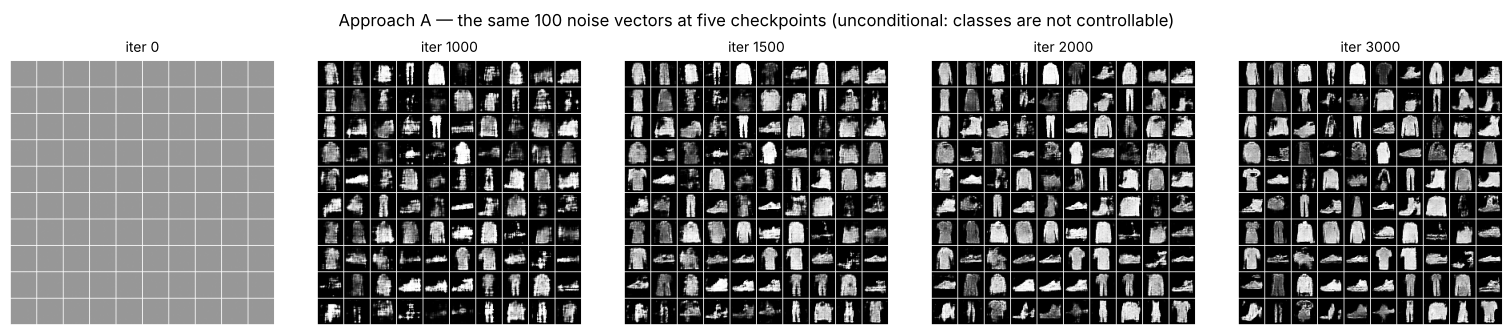

In [8]:
def progress_figure(hist: dict, n_show: int = 5, nrow: int = 10, title: str = "") -> None:
    """Sample grids from the same fixed noise at evenly spaced checkpoints (the brief: 'save grids throughout training')."""
    sel = np.linspace(0, len(hist["grids"]) - 1, n_show).round().astype(int)
    fig, axes = plt.subplots(1, n_show, figsize=(3.1 * n_show, 3.3))
    for ax, i in zip(axes, sel):
        show_grid(hist["grids"][i], nrow, ax, f"iter {hist['grid_iter'][i]}")
    fig.suptitle(title, y=1.0)
    plt.tight_layout()
    plt.show()


progress_figure(HIST_A, 5, 10, "Approach A — the same 100 noise vectors at five checkpoints (unconditional: classes are not controllable)")

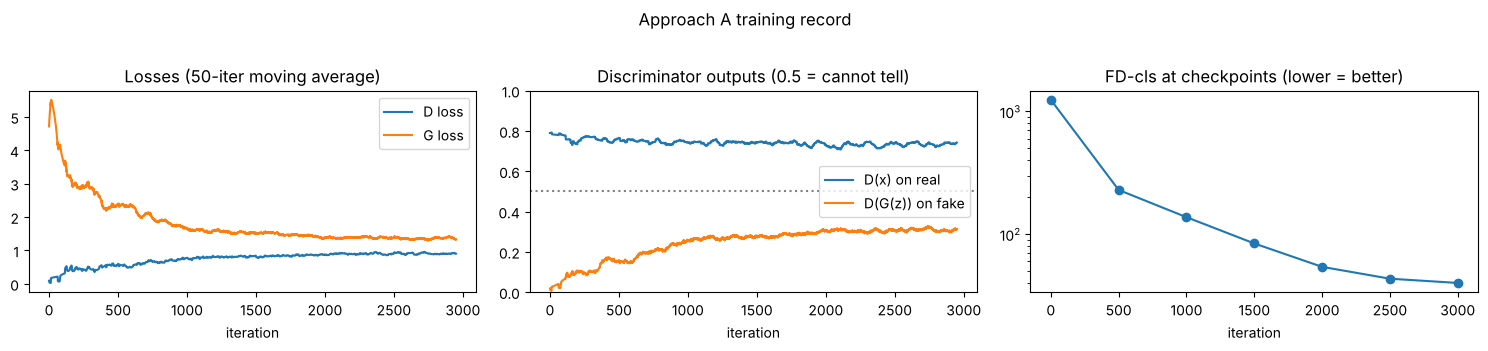

class histogram of 2000 samples at each checkpoint (rows = checkpoints; columns = classifier labels):
iter  T-shir  Trouse  Pullov  Dress  Coat   Sandal  Shirt  Sneake  Bag    Boot   entropy
----  ------  ------  ------  -----  -----  ------  -----  ------  -----  -----  -------
0     0.000   0.000   0.000   0.000  0.000  0.000   0.000  0.000   1.000  0.000  0.000  
500   0.030   0.056   0.038   0.200  0.160  0.116   0.091  0.035   0.188  0.087  0.920  
1000  0.038   0.080   0.050   0.184  0.140  0.155   0.115  0.064   0.114  0.061  0.952  
1500  0.040   0.105   0.077   0.164  0.120  0.090   0.102  0.091   0.092  0.118  0.979  
2000  0.074   0.111   0.097   0.131  0.130  0.073   0.066  0.107   0.081  0.131  0.987  
2500  0.082   0.118   0.093   0.135  0.098  0.086   0.082  0.100   0.086  0.122  0.993  
3000  0.076   0.119   0.111   0.142  0.100  0.062   0.064  0.123   0.086  0.117  0.985  


In [9]:
def training_curves(hist: dict, title: str) -> None:
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
    k = 50
    sm = lambda a: np.convolve(np.nan_to_num(a, nan=np.nanmean(a)), np.ones(k) / k, mode="valid")  # noqa: E731
    ax[0].plot(sm(hist["loss_d"]), label="D loss")
    ax[0].plot(sm(hist["loss_g"]), label="G loss")
    ax[0].set(title="Losses (50-iter moving average)", xlabel="iteration")
    ax[0].legend()
    ax[1].plot(sm(hist["d_real"]), label="D(x) on real")
    ax[1].plot(sm(hist["d_fake"]), label="D(G(z)) on fake")
    ax[1].axhline(0.5, color="gray", ls=":")
    ax[1].set(title="Discriminator outputs (0.5 = cannot tell)", xlabel="iteration", ylim=(0, 1))
    ax[1].legend()
    ax[2].plot(hist["ckpt_iter"], hist["ckpt_fd_cls"], "o-")
    ax[2].set(title="FD-cls at checkpoints (lower = better)", xlabel="iteration", yscale="log")
    fig.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()


training_curves(HIST_A, "Approach A training record")
print("class histogram of 2000 samples at each checkpoint (rows = checkpoints; columns = classifier labels):")
table([[it] + [f"{v:.3f}" for v in h] + [f"{e:.3f}"] for it, h, e in zip(HIST_A["ckpt_iter"], HIST_A["ckpt_class_hist"], HIST_A["ckpt_entropy"])],
      ["iter"] + [c[:6] for c in CLASS_NAMES] + ["entropy"])

# Part 3 — Approach B: class-conditioned GAN (§6)
**What changes relative to A (and nothing else does):** the class label is fed to *both* networks. The generator receives `[z, one-hot(y)]` as input channels; the discriminator receives the image plus the one-hot label broadcast as ten constant extra channels, so it judges *"is this a realistic image **of class y**?"*. Everything else — layer widths, loss, optimiser, batch, iterations, noise seed — is identical to A, so any difference in the results is attributable to conditioning.
Note: the discriminator here only ever sees (real image, true label) versus (generated image, requested label). A common refinement that adds (real image, *wrong* label) negatives to sharpen label consistency is **not** used, to keep B a minimal change from A.

In [10]:
seed_all()
G_B, D_B = DCGenerator(CFG["nz"], CFG["ng"], n_cls=10).to(DEVICE), DCDiscriminator(CFG["ng"], n_cls=10).to(DEVICE)
config_table([
    ("generator", f"as A, input = [z (100) ; one-hot class (10)] | {n_params(G_B):,} parameters"),
    ("discriminator", f"as A, input = image + 10 label channels | {n_params(D_B):,} parameters"),
    ("generator loss / optimiser", "identical to A (non-saturating, Adam 2e-4, beta1 0.5)"),
    ("batch / iterations / seed", f"{CFG['batch']} / {CFG['iters']} / {SEED}  (identical to A)"),
    ("conditioning labels", "true Fashion-MNIST labels for real pairs; uniformly random labels for generated pairs"),
])
print(f"\ntraining B for {CFG['iters']} iterations ...")
HIST_B = train_gan("B: cGAN", G_B, D_B, CFG["iters"])
print(f"[measured] B trained in {HIST_B['seconds']:.0f} s ({HIST_B['iters_per_sec']:.1f} it/s)")

setting                     value                                                                                
--------------------------  -------------------------------------------------------------------------------------
generator                   as A, input = [z (100) ; one-hot class (10)] | 390,081 parameters                    
discriminator               as A, input = image + 10 label channels | 171,937 parameters                         
generator loss / optimiser  identical to A (non-saturating, Adam 2e-4, beta1 0.5)                                
batch / iterations / seed   64 / 3000 / 17  (identical to A)                                                     
conditioning labels         true Fashion-MNIST labels for real pairs; uniformly random labels for generated pairs

training B for 3000 iterations ...


  [B: cGAN] iter     0  FD-cls 1138.27  class-entropy 0.000  D(x) nan  D(G(z)) nan  (1 s)


  [B: cGAN] iter   500  FD-cls  159.63  class-entropy 0.985  D(x) 0.81  D(G(z)) 0.19  (51 s)


  [B: cGAN] iter  1000  FD-cls   82.46  class-entropy 0.990  D(x) 0.75  D(G(z)) 0.20  (100 s)


  [B: cGAN] iter  1500  FD-cls   40.97  class-entropy 0.996  D(x) 0.75  D(G(z)) 0.28  (151 s)


  [B: cGAN] iter  2000  FD-cls   38.14  class-entropy 0.993  D(x) 0.72  D(G(z)) 0.31  (202 s)


  [B: cGAN] iter  2500  FD-cls   27.31  class-entropy 0.998  D(x) 0.68  D(G(z)) 0.33  (252 s)


  [B: cGAN] iter  3000  FD-cls   16.27  class-entropy 0.999  D(x) 0.71  D(G(z)) 0.32  (302 s)
[measured] B trained in 302 s (9.9 it/s)


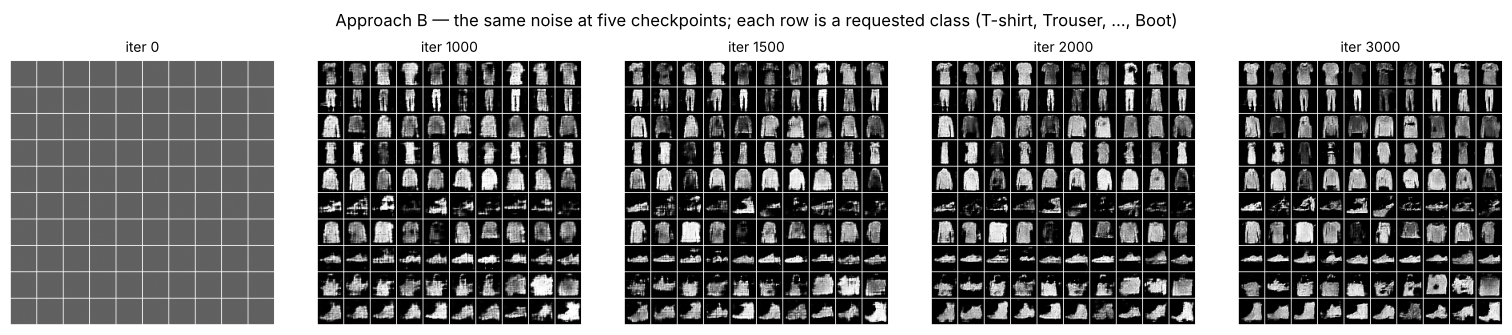

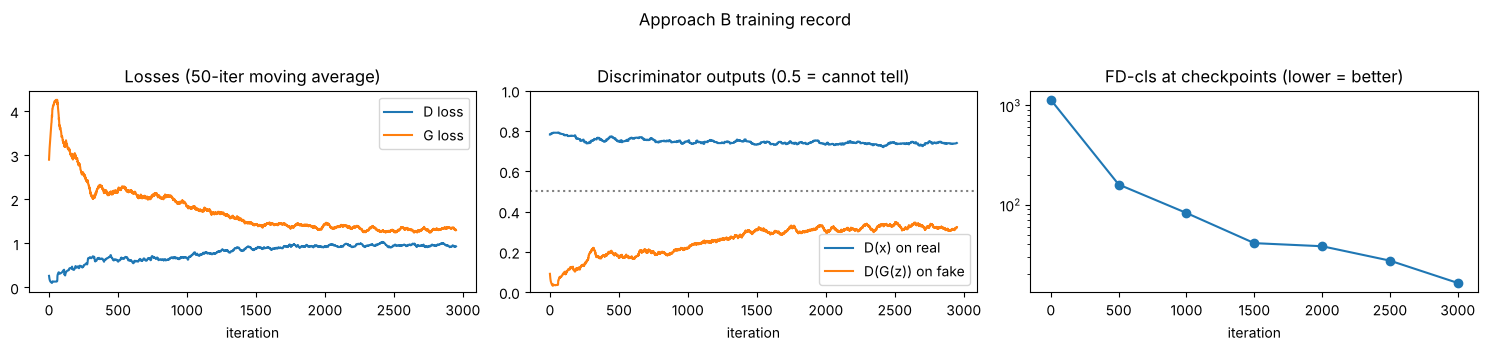

In [11]:
progress_figure(HIST_B, 5, 10, "Approach B — the same noise at five checkpoints; each row is a requested class (T-shirt, Trouser, ..., Boot)")
training_curves(HIST_B, "Approach B training record")

### Controllability demonstration (the brief: "controllability demonstrated against the unconditional baseline")
Two tests, both on the final models:
1. **Same noise, different class.** Each row uses one noise vector and walks through all 10 requested classes. If conditioning works, the class changes while the noise-driven style (size, brightness, texture) persists along the row.
2. **Does the output match the request?** For B the requested class is an input, so the reference classifier's agreement with the request is measured per class. A has no such input; what A would give for a random request is compared in Part 6.

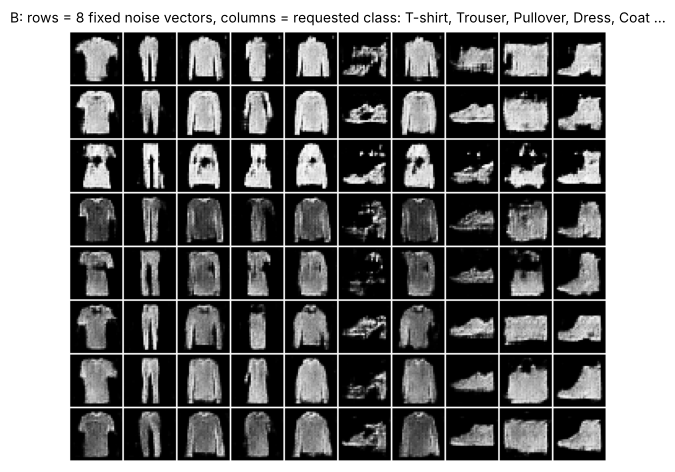

[measured] B: requested class recovered by the reference classifier, per class:
requested  agreement
---------  ---------
T-shirt    0.864    
Trouser    0.978    
Pullover   0.654    
Dress      0.942    
Coat       0.668    
Sandal     0.960    
Shirt      0.564    
Sneaker    0.882    
Bag        0.922    
Boot       0.940    
ALL        0.837    


In [12]:
z_demo = torch.randn(8, CFG["nz"], 1, 1, generator=torch.Generator().manual_seed(SEED + 7)).to(DEVICE)
G_B.eval()
with torch.no_grad():
    rows = [G_B(z_demo[i:i + 1].repeat(10, 1, 1, 1), torch.arange(10, device=DEVICE)).cpu() for i in range(8)]
G_B.train()
fig, ax = plt.subplots(figsize=(8, 5.6))
show_grid(torch.cat(rows), 10, ax, "B: rows = 8 fixed noise vectors, columns = requested class: " + ", ".join(CLASS_NAMES[:5]) + " ...")
plt.show()

imgs_b, req_b = sample_generator(G_B, CFG["n_eval"], seed=SEED + 2)
probs_b, _ = classify(CLF, imgs_b)
acc_b = (probs_b.argmax(1) == req_b).float().numpy()
per_class = [acc_b[req_b.numpy() == c].mean() for c in range(10)]
print("[measured] B: requested class recovered by the reference classifier, per class:")
table([[CLASS_NAMES[c], f"{per_class[c]:.3f}"] for c in range(10)] + [["ALL", f"{acc_b.mean():.3f}"]], ["requested", "agreement"])

# Part 4 — Approach C: image-to-image translation with pix2pix (§7.1)
**Task (constructed, see scope note):** translate a Sobel **edge map** into the clothing image it came from. pix2pix (Isola et al., CVPR 2017) is a *conditional* GAN on whole images:
* **Generator = U-Net** (encoder–decoder with skip connections, so the edge locations pass straight through to the output); dropout in the first decoder layers is the only noise source, as in the paper.
* **Discriminator = PatchGAN**: it classifies every local patch of the (edge map, image) pair as real/fake, which penalises wrong local texture rather than judging the whole image.
* **Loss = adversarial + λ·L1** with λ = 100, the paper's default. The L1 term anchors the output to the ground truth; the brief's tip about tuning the cycle-consistency weight applies to CycleGAN, which I did *not* choose, so I instead test the analogous question here: *does the adversarial term help at all?* — by training an identical **L1-only** U-Net (no discriminator) with the same budget.

Why pix2pix and not CycleGAN: the brief allows either, and paired data exist for this task by construction. pix2pix has a ground truth to score against (L1, PSNR, SSIM), which CycleGAN would not.

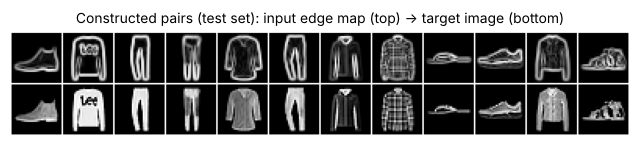

In [13]:
def sobel_edges(x: torch.Tensor) -> torch.Tensor:
    """x in [-1,1], (N,1,H,W) -> soft edge map in [-1,1] (Sobel gradient magnitude, normalised per image by its own maximum)."""
    img = x.add(1).div(2)
    kx = torch.tensor([[-1.0, 0.0, 1.0], [-2.0, 0.0, 2.0], [-1.0, 0.0, 1.0]], device=x.device).view(1, 1, 3, 3)
    gx, gy = F.conv2d(img, kx, padding=1), F.conv2d(img, kx.transpose(2, 3), padding=1)
    mag = torch.sqrt(gx ** 2 + gy ** 2 + 1e-8)
    mag = mag / mag.amax(dim=(1, 2, 3), keepdim=True).clamp_min(1e-6)
    return mag * 2 - 1


E_TR, E_TE = sobel_edges(X_TR), sobel_edges(X_TE)
fig, ax = plt.subplots(figsize=(8, 2.2))
show_grid(torch.cat([E_TE[:12], X_TE[:12]]), 12, ax, "Constructed pairs (test set): input edge map (top) -> target image (bottom)")
plt.show()


def down(cin: int, cout: int, bn: bool = True) -> nn.Sequential:
    layers: list[nn.Module] = [nn.Conv2d(cin, cout, 4, 2, 1, bias=not bn)]
    if bn:
        layers.append(nn.BatchNorm2d(cout))
    return nn.Sequential(*layers)


def up(cin: int, cout: int, drop: bool = False) -> nn.Sequential:
    layers: list[nn.Module] = [nn.ConvTranspose2d(cin, cout, 4, 2, 1, bias=False), nn.BatchNorm2d(cout)]
    if drop:
        layers.append(nn.Dropout(0.5))
    return nn.Sequential(*layers)


class UNetGenerator(nn.Module):
    """32x32 -> 16 -> 8 -> 4 -> 2 (bottleneck) and back, with skip connections between mirrored layers."""

    def __init__(self, ng: int = 64) -> None:
        super().__init__()
        self.e1, self.e2, self.e3, self.e4 = down(1, ng, bn=False), down(ng, ng * 2), down(ng * 2, ng * 4), down(ng * 4, ng * 8)
        self.d4, self.d3, self.d2 = up(ng * 8, ng * 4, drop=True), up(ng * 8, ng * 2, drop=True), up(ng * 4, ng)
        self.out = nn.ConvTranspose2d(ng * 2, 1, 4, 2, 1)
        self.apply(init_weights)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        e1 = self.e1(x)                                # 16
        e2 = self.e2(F.leaky_relu(e1, 0.2))            # 8
        e3 = self.e3(F.leaky_relu(e2, 0.2))            # 4
        e4 = self.e4(F.leaky_relu(e3, 0.2))            # 2
        d4 = self.d4(F.relu(e4))                       # 4
        d3 = self.d3(F.relu(torch.cat([d4, e3], 1)))   # 8
        d2 = self.d2(F.relu(torch.cat([d3, e2], 1)))   # 16
        return torch.tanh(self.out(F.relu(torch.cat([d2, e1], 1))))  # 32


class PatchDiscriminator(nn.Module):
    """Judges (edge, image) pairs patch by patch: output is a 6x6 grid of real/fake logits."""

    def __init__(self, ndf: int = 64) -> None:
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(2, ndf, 4, 2, 1), nn.LeakyReLU(0.2, True),                                       # 16
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf * 2), nn.LeakyReLU(0.2, True),  # 8
            nn.Conv2d(ndf * 2, ndf * 4, 4, 1, 1, bias=False), nn.BatchNorm2d(ndf * 4), nn.LeakyReLU(0.2, True),  # 7
            nn.Conv2d(ndf * 4, 1, 4, 1, 1),                                                            # 6x6 logits
        )
        self.apply(init_weights)

    def forward(self, edge: torch.Tensor, img: torch.Tensor) -> torch.Tensor:
        return self.net(torch.cat([edge, img], 1))


@torch.no_grad()
def translate(G: UNetGenerator, edges: torch.Tensor, bs: int = 500) -> torch.Tensor:
    was = G.training
    G.eval()  # deterministic: dropout off
    out = torch.cat([G(edges[i:i + bs].to(DEVICE)).cpu() for i in range(0, len(edges), bs)])
    G.train(was)
    return out


def train_pix2pix(tag: str, iters: int, *, use_gan: bool = True, lam: float = 100.0, seed: int = SEED, verbose: bool = True) -> tuple[UNetGenerator, dict]:
    seed_all(seed)
    G = UNetGenerator(CFG["ndf_p2p"]).to(DEVICE)
    D = PatchDiscriminator(CFG["ndf_p2p"]).to(DEVICE) if use_gan else None
    bs = CFG["batch"]
    opt_g = torch.optim.Adam(G.parameters(), CFG["lr"], betas=(CFG["beta1"], 0.999))
    opt_d = torch.optim.Adam(D.parameters(), CFG["lr"], betas=(CFG["beta1"], 0.999)) if use_gan else None
    bce = nn.BCEWithLogitsLoss()
    hist = dict(tag=tag, loss_d=[], loss_g=[], loss_l1=[], d_real=[], d_fake=[], ckpt_iter=[], ckpt_fd_cls=[], ckpt_l1=[], grids=[], grid_iter=[])
    n_mon = CFG["n_monitor"]
    fixed_e = E_TE[:40].to(DEVICE)
    perm, ptr, n_data = torch.randperm(X_TR.shape[0], device=DEVICE), 0, X_TR.shape[0]
    t0 = time.time()

    def checkpoint(it: int) -> None:
        hist["grids"].append(translate(G, fixed_e))
        hist["grid_iter"].append(it)
        out = translate(G, E_TE[:n_mon])
        hist["ckpt_iter"].append(it)
        hist["ckpt_fd_cls"].append(EVAL.fd_cls(out))
        hist["ckpt_l1"].append(float((out - X_TE[:n_mon].cpu()).abs().mean()))
        if verbose:
            print(f"  [{tag}] iter {it:5d}  FD-cls {hist['ckpt_fd_cls'][-1]:7.2f}  test L1 {hist['ckpt_l1'][-1]:.4f}  ({time.time() - t0:.0f} s)")

    G.train()
    if D is not None:
        D.train()
    checkpoint(0)
    for it in range(1, iters + 1):
        if ptr + bs > n_data:
            perm, ptr = torch.randperm(n_data, device=DEVICE), 0
        idx = perm[ptr:ptr + bs]
        ptr += bs
        real, edge = X_TR[idx], E_TR[idx]
        fake = G(edge)
        if D is not None:
            lr_, lf_ = D(edge, real), D(edge, fake.detach())
            ld = 0.5 * (bce(lr_, torch.ones_like(lr_)) + bce(lf_, torch.zeros_like(lf_)))
            opt_d.zero_grad(set_to_none=True)
            ld.backward()
            opt_d.step()
            logits = D(edge, fake)
            l_gan = bce(logits, torch.ones_like(logits))
            hist["loss_d"].append(float(ld.detach()))
            hist["d_fake"].append(float(torch.sigmoid(logits).mean().detach()))
            hist["d_real"].append(float(torch.sigmoid(lr_).mean().detach()) if it % 5 == 0 else float("nan"))
        else:
            l_gan = torch.zeros((), device=DEVICE)
        l1 = F.l1_loss(fake, real)
        loss = l_gan + lam * l1
        opt_g.zero_grad(set_to_none=True)
        loss.backward()
        opt_g.step()
        hist["loss_g"].append(float(l_gan.detach()))
        hist["loss_l1"].append(float(l1.detach()))
        if it % CFG["eval_every"] == 0:
            checkpoint(it)
    hist["seconds"] = time.time() - t0
    hist["iters"] = iters
    hist["iters_per_sec"] = iters / hist["seconds"]
    return G, hist

In [14]:
seed_all()
_g, _d = UNetGenerator(CFG["ndf_p2p"]), PatchDiscriminator(CFG["ndf_p2p"])
config_table([
    ("generator", f"U-Net (4 down / 3 up + skips, dropout 0.5 in 2 decoder layers) | {n_params(_g):,} parameters"),
    ("discriminator", f"PatchGAN, 6x6 logit grid | {n_params(_d):,} parameters"),
    ("loss", "BCE(D(edge, G(edge)), 1) + 100 * L1(G(edge), target); D loss halved as in the paper"),
    ("optimiser / batch / iterations", f"Adam 2e-4, beta1 0.5 / {CFG['batch']} / {CFG['iters']} (identical to A and B)"),
    ("pairs", "edge map of each Fashion-MNIST train image -> that image (60 000 pairs); test pairs held out"),
    ("baseline", "identical U-Net trained with the L1 term only (no discriminator)"),
])
del _g, _d
print(f"\ntraining pix2pix for {CFG['iters']} iterations ...")
G_C, HIST_C = train_pix2pix("C: pix2pix", CFG["iters"])
print(f"[measured] pix2pix trained in {HIST_C['seconds']:.0f} s ({HIST_C['iters_per_sec']:.1f} it/s)")
print(f"\ntraining the L1-only baseline for {CFG['iters']} iterations ...")
G_L1, HIST_L1 = train_pix2pix("C-baseline: L1 only", CFG["iters"], use_gan=False)
print(f"[measured] L1-only baseline trained in {HIST_L1['seconds']:.0f} s ({HIST_L1['iters_per_sec']:.1f} it/s)")

setting                         value                                                                                       
------------------------------  --------------------------------------------------------------------------------------------
generator                       U-Net (4 down / 3 up + skips, dropout 0.5 in 2 decoder layers) | 1,543,009 parameters       
discriminator                   PatchGAN, 6x6 logit grid | 167,329 parameters                                               
loss                            BCE(D(edge, G(edge)), 1) + 100 * L1(G(edge), target); D loss halved as in the paper         
optimiser / batch / iterations  Adam 2e-4, beta1 0.5 / 64 / 3000 (identical to A and B)                                     
pairs                           edge map of each Fashion-MNIST train image -> that image (60 000 pairs); test pairs held out
baseline                        identical U-Net trained with the L1 term only (no discriminator)                            


  [C: pix2pix] iter     0  FD-cls 1131.50  test L1 0.7490  (1 s)


  [C: pix2pix] iter   500  FD-cls   16.63  test L1 0.0942  (82 s)


  [C: pix2pix] iter  1000  FD-cls    4.96  test L1 0.0951  (161 s)


  [C: pix2pix] iter  1500  FD-cls    3.75  test L1 0.0773  (240 s)


  [C: pix2pix] iter  2000  FD-cls    2.97  test L1 0.0739  (321 s)


... (5 outputs left out)

  [C-baseline: L1 only] iter  1500  FD-cls    8.73  test L1 0.0711  (122 s)


  [C-baseline: L1 only] iter  2000  FD-cls    7.20  test L1 0.0702  (160 s)


  [C-baseline: L1 only] iter  2500  FD-cls    6.56  test L1 0.0662  (199 s)


  [C-baseline: L1 only] iter  3000  FD-cls    5.26  test L1 0.0631  (237 s)
[measured] L1-only baseline trained in 237 s (12.6 it/s)


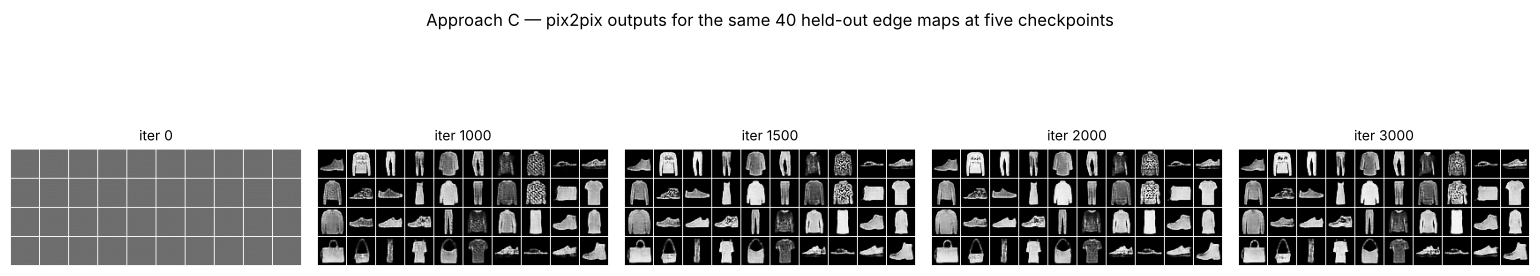

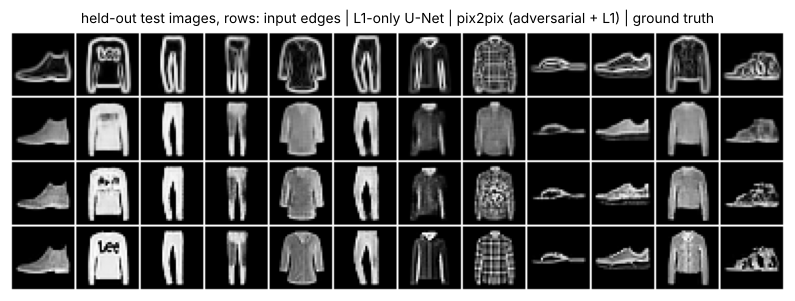

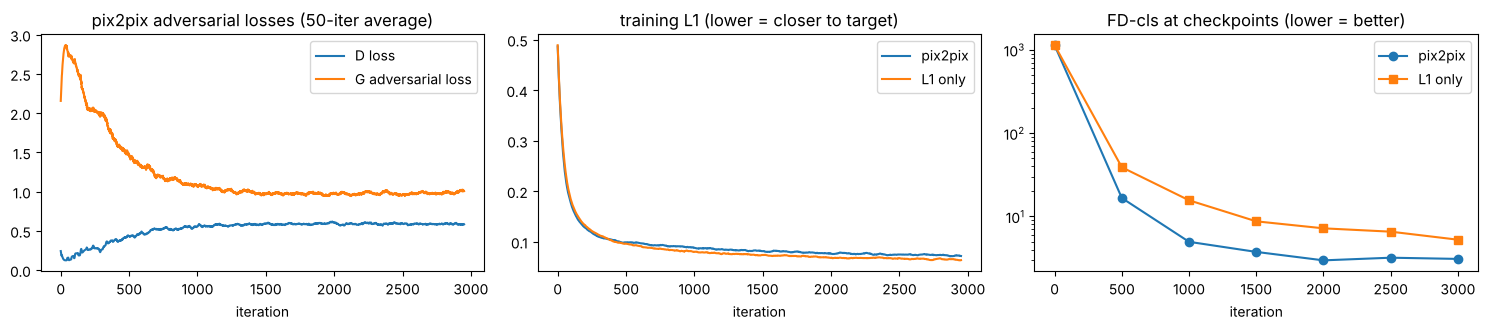

In [15]:
sel = np.linspace(0, len(HIST_C["grids"]) - 1, 5).round().astype(int)
fig, axes = plt.subplots(1, 5, figsize=(15.5, 3.6))
for ax, i in zip(axes, sel):
    show_grid(HIST_C["grids"][i], 10, ax, f"iter {HIST_C['grid_iter'][i]}")
fig.suptitle("Approach C — pix2pix outputs for the same 40 held-out edge maps at five checkpoints", y=1.0)
plt.tight_layout()
plt.show()

k = 12
fig, ax = plt.subplots(figsize=(10, 3.9))
show_grid(torch.cat([E_TE[:k].cpu(), translate(G_L1, E_TE[:k]), translate(G_C, E_TE[:k]), X_TE[:k].cpu()]), k, ax,
          "held-out test images, rows: input edges | L1-only U-Net | pix2pix (adversarial + L1) | ground truth")
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
sm = lambda a: np.convolve(a, np.ones(50) / 50, mode="valid")  # noqa: E731
ax[0].plot(sm(HIST_C["loss_d"]), label="D loss")
ax[0].plot(sm(HIST_C["loss_g"]), label="G adversarial loss")
ax[0].set(title="pix2pix adversarial losses (50-iter average)", xlabel="iteration")
ax[0].legend()
ax[1].plot(sm(HIST_C["loss_l1"]), label="pix2pix")
ax[1].plot(sm(HIST_L1["loss_l1"]), label="L1 only")
ax[1].set(title="training L1 (lower = closer to target)", xlabel="iteration")
ax[1].legend()
ax[2].plot(HIST_C["ckpt_iter"], HIST_C["ckpt_fd_cls"], "o-", label="pix2pix")
ax[2].plot(HIST_L1["ckpt_iter"], HIST_L1["ckpt_fd_cls"], "s-", label="L1 only")
ax[2].set(title="FD-cls at checkpoints (lower = better)", xlabel="iteration", yscale="log")
ax[2].legend()
plt.tight_layout()
plt.show()

# Part 5 — Training stability against §4's failure modes
The brief asks which of mode collapse (§4.1), instability (§4.2) and an overpowered discriminator (§4.3) were encountered, and how they were diagnosed. Two things are done:
1. **Automatic diagnostics on the real A and B runs**, with thresholds fixed *before* looking at the results `[assumed]`:
   * *mode collapse* — class entropy of 2000 samples falls below 0.90 (1.0 = even) or one class falls under 3 % of the samples, at any checkpoint after the first 25 % of training;
   * *overpowered discriminator* — mean D(G(z)) over the last 20 % of training is below 0.10 (D almost never fooled);
   * *instability* — FD-cls rises by more than 50 % between consecutive checkpoints in the second half of training.
   The detector itself was validated in Part 1: the single-class set has class entropy ≈ 0.
2. **Two deliberate provocations of A** (same seed, same budget, 1000 iterations each) so that a failure mode is actually observed and diagnosed rather than only described: (i) the original *saturating* minimax generator loss (§3.4), (ii) a discriminator updated 3× per generator update (§4.3). The baseline for both is run A at the same iteration, from its own log.

In [16]:
def late_mean(a: list[float], frac: float = 0.2) -> float:
    a = np.array(a, dtype=float)
    a = a[int(len(a) * (1 - frac)):]
    return float(np.nanmean(a))


def diagnose(hist: dict, conditional_acc: float | None = None) -> dict:
    it = np.array(hist["ckpt_iter"])
    late = it >= 0.25 * it.max()
    ent, share = np.array(hist["ckpt_entropy"]), np.array(hist["ckpt_min_share"])
    fd = np.array(hist["ckpt_fd_cls"])
    second_half = np.where(it >= 0.5 * it.max())[0]
    ratios = [fd[i] / fd[i - 1] for i in second_half if i > 0]
    d_fake_late = late_mean(hist["d_fake"])
    d_real_late = late_mean(hist["d_real"])
    res = dict(
        min_entropy_late=float(ent[late].min()), min_share_late=float(share[late].min()),
        d_real_late=d_real_late, d_fake_late=d_fake_late, max_fd_ratio=float(max(ratios)) if ratios else float("nan"),
        mode_collapse=bool((ent[late] < 0.90).any() or (share[late] < 0.03).any()),
        overpowered_d=bool(d_fake_late < 0.10),
        unstable=bool(ratios and max(ratios) > 1.5),
    )
    return res


DIAG_A, DIAG_B = diagnose(HIST_A), diagnose(HIST_B)
rows = []
for name, d in [("A: DCGAN", DIAG_A), ("B: cGAN", DIAG_B)]:
    rows.append([name, f"{d['min_entropy_late']:.3f}", f"{d['min_share_late']:.3f}", f"{d['d_real_late']:.2f} / {d['d_fake_late']:.2f}",
                 f"{d['max_fd_ratio']:.2f}", "yes" if d["mode_collapse"] else "no", "yes" if d["overpowered_d"] else "no", "yes" if d["unstable"] else "no"])
table(rows, ["run", "min class entropy", "min class share", "late D(x) / D(G(z))", "max FD ratio (2nd half)", "mode collapse?", "overpowered D?", "unstable?"])
print("\n(thresholds: entropy < 0.90 or share < 0.03 | late D(G(z)) < 0.10 | FD ratio > 1.5)")

run       min class entropy  min class share  late D(x) / D(G(z))  max FD ratio (2nd half)  mode collapse?  overpowered D?  unstable?
--------  -----------------  ---------------  -------------------  -----------------------  --------------  --------------  ---------
A: DCGAN  0.952              0.038            0.70 / 0.31          0.92                     no              no              no       
B: cGAN   0.990              0.064            0.70 / 0.32          0.93                     no              no              no       

(thresholds: entropy < 0.90 or share < 0.03 | late D(G(z)) < 0.10 | FD ratio > 1.5)


running ablation 1: saturating minimax generator loss ...


running ablation 2: discriminator updated 3x per generator step ...


run (identical seed)         mean |grad G| first 200 it  D(G(z)) first 200 it  D(G(z)) it 800-1000  FD-cls @ it 1000  class entropy @ it 1000
---------------------------  --------------------------  --------------------  -------------------  ----------------  -----------------------
baseline A (non-saturating)  24.034                      0.050                 0.226                137.4             0.952                  
minimax (saturating) G loss  0.041                       0.005                 0.000                705.3             0.802                  
D updated 3x per G step      28.898                      0.041                 0.090                99.5              0.968                  


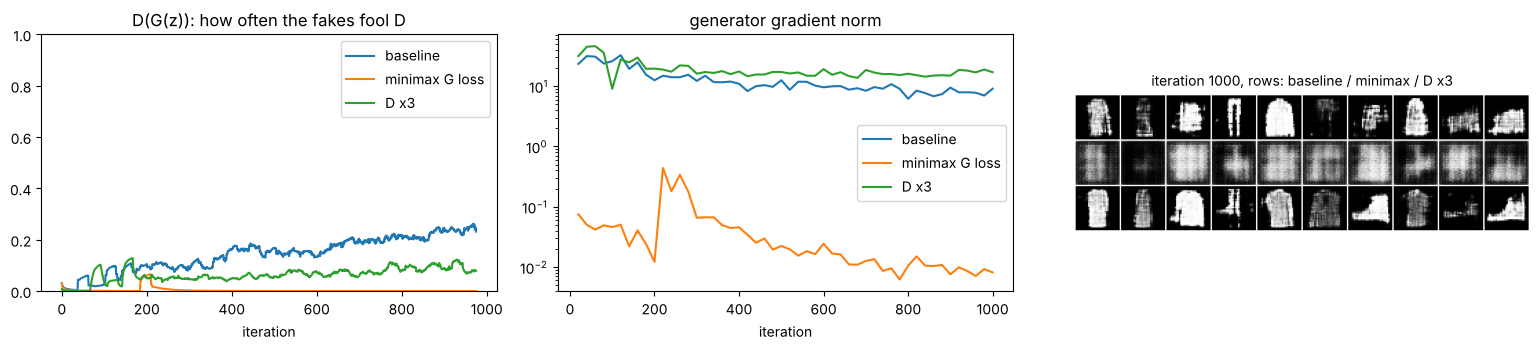

In [17]:
print("running ablation 1: saturating minimax generator loss ...")
seed_all()
G_S, D_S = DCGenerator(CFG["nz"], CFG["ng"]).to(DEVICE), DCDiscriminator(CFG["ng"]).to(DEVICE)
HIST_SAT = train_gan("ablation: minimax G loss", G_S, D_S, CFG["abl_iters"], g_loss="minimax", verbose=False)
print("running ablation 2: discriminator updated 3x per generator step ...")
seed_all()
G_O, D_O = DCGenerator(CFG["nz"], CFG["ng"]).to(DEVICE), DCDiscriminator(CFG["ng"]).to(DEVICE)
HIST_OVER = train_gan("ablation: D x3", G_O, D_O, CFG["abl_iters"], d_steps=3, verbose=False)


def gnorm_early(h: dict, n_its: int = 200) -> float:
    return float(np.mean([g for it, g in h["gnorm"] if it <= n_its]))


def at_iter(h: dict, key: str, it: int) -> float:
    return float(h[key][h["ckpt_iter"].index(it)])


ai = CFG["abl_iters"]
rows = []
for name, h in [("baseline A (non-saturating)", HIST_A), ("minimax (saturating) G loss", HIST_SAT), ("D updated 3x per G step", HIST_OVER)]:
    rows.append([name, f"{gnorm_early(h):.3f}", f"{np.mean(h['d_fake'][:200]):.3f}", f"{np.mean(h['d_fake'][ai - 200:ai]):.3f}",
                 f"{at_iter(h, 'ckpt_fd_cls', ai):.1f}", f"{at_iter(h, 'ckpt_entropy', ai):.3f}"])
table(rows, ["run (identical seed)", "mean |grad G| first 200 it", "D(G(z)) first 200 it", f"D(G(z)) it {ai - 200}-{ai}", f"FD-cls @ it {ai}", f"class entropy @ it {ai}"])

fig, ax = plt.subplots(1, 3, figsize=(15.5, 3.6))
for h, lab in [(HIST_A, "baseline"), (HIST_SAT, "minimax G loss"), (HIST_OVER, "D x3")]:
    ax[0].plot(np.convolve(h["d_fake"][:ai], np.ones(25) / 25, mode="valid"), label=lab)
    ax[1].plot([it for it, _ in h["gnorm"] if it <= ai], [g for it, g in h["gnorm"] if it <= ai], label=lab)
ax[0].set(title="D(G(z)): how often the fakes fool D", xlabel="iteration", ylim=(0, 1))
ax[0].legend()
ax[1].set(title="generator gradient norm", xlabel="iteration", yscale="log")
ax[1].legend()
for h, lab in [(HIST_A, "baseline"), (HIST_SAT, "minimax G loss"), (HIST_OVER, "D x3")]:
    sel_i = [i for i, it in enumerate(h["grid_iter"]) if it == ai][0]
    if lab == "baseline":
        base_grid = h["grids"][sel_i]
sat_grid, over_grid = HIST_SAT["grids"][-1], HIST_OVER["grids"][-1]
show_grid(torch.cat([base_grid[:10], sat_grid[:10], over_grid[:10]]), 10, ax[2], f"iteration {ai}, rows: baseline / minimax / D x3")
plt.tight_layout()
plt.show()

# Part 6 — Head-to-head comparison under one protocol (§9.5)
All three approaches are scored by the same `Evaluator` (Part 1): same reference set, same sample count, same networks, same code. The qualitative grids further down use one fixed set of criteria for every approach: **realism** (precision), **diversity** (recall, class histogram) and **correctness against the condition** (conditional accuracy; only defined for B and C).
**Uncertainty.** Two sources are quantified: *sampling* spread of the generated set (5 disjoint folds, below) and *training-run* variance (Part 6b: A and B re-trained with a second seed). C and its L1-only baseline have a single seed, so any difference between them is tentative.
**What is *not* like-for-like, and is stated rather than hidden:** C receives an edge map and therefore has far more information than A or B, so its FID/precision/recall are expected to be better for that reason alone; they quantify what the *task* allows, not that the architecture is superior.

In [18]:
from torch.utils.flop_counter import FlopCounterMode

n = CFG["n_eval"]
t0 = time.time()
imgs_a, _ = sample_generator(G_A, n, seed=SEED + 2)
imgs_c = translate(G_C, E_TE[:n])
imgs_l1 = translate(G_L1, E_TE[:n])
RES = {
    "A: DCGAN": EVAL.score(imgs_a),
    "B: cGAN": EVAL.score(imgs_b, requested=req_b),
    "C: pix2pix": EVAL.score(imgs_c, requested=Y_TE[:n]),
    "C-baseline: L1 only": EVAL.score(imgs_l1, requested=Y_TE[:n]),
}
RES["real train images (floor)"] = CHECKS["real train images (noise floor)"]
print(f"evaluation done in {time.time() - t0:.0f} s")


def psnr(a: torch.Tensor, b: torch.Tensor) -> float:
    mse = ((a.add(1).div(2) - b.add(1).div(2)) ** 2).mean(dim=(1, 2, 3))
    return float((10 * torch.log10(1.0 / mse.clamp_min(1e-10))).mean())


gt = X_TE[:n].cpu()
for k, im in [("C: pix2pix", imgs_c), ("C-baseline: L1 only", imgs_l1)]:
    RES[k]["l1"] = float((im - gt).abs().mean())
    RES[k]["psnr"] = psnr(im, gt)
    RES[k]["ssim"] = float(np.mean([structural_similarity(im[i, 0].numpy(), gt[i, 0].numpy(), data_range=2.0) for i in range(len(im))]))


def fold_fd_cls(feats: np.ndarray, k: int = 5) -> tuple[float, float]:
    """Sampling spread of FD-cls: split the generated set into k disjoint folds (no resampling, so no duplicate-induced bias) and
    score each fold of n/k images against the same reference. Mean/sd are for sets of n/k images, so they sit above the full-n value."""
    parts = np.array_split(feats, k)
    vals = [frechet_distance(p_, EVAL.ref_cls_np) for p_ in parts]
    return float(np.mean(vals)), float(np.std(vals, ddof=1))


for k in ["A: DCGAN", "B: cGAN", "C: pix2pix", "C-baseline: L1 only", "real train images (floor)"]:
    RES[k]["fd_cls_folds"] = fold_fd_cls(RES[k]["_cls_feats"])

# compute cost: parameters, forward FLOPs for ONE sample, wall-clock training, inference throughput
def gflops(fn, *args) -> float:
    with FlopCounterMode(display=False) as fc:
        with torch.no_grad():
            fn(*args)
    return fc.get_total_flops() / 1e9


def infer_ms_per_image(fn, make_input, reps: int = 5) -> float:
    x = make_input(500)
    fn(*x)
    t = time.time()
    for _ in range(reps):
        fn(*x)
    return (time.time() - t) / (reps * 500) * 1000


G_A.eval(); G_B.eval(); G_C.eval()
zc = lambda m: torch.randn(m, CFG["nz"], 1, 1, device=DEVICE)  # noqa: E731
yc = lambda m: torch.randint(0, 10, (m,), device=DEVICE)  # noqa: E731
COST = {
    "A: DCGAN": dict(params=n_params(G_A) + n_params(D_A), gparams=n_params(G_A), gflops=gflops(G_A, zc(1)),
                     seconds=HIST_A["seconds"], ms_img=infer_ms_per_image(lambda z: G_A(z), lambda m: (zc(m),))),
    "B: cGAN": dict(params=n_params(G_B) + n_params(D_B), gparams=n_params(G_B), gflops=gflops(G_B, zc(1), yc(1)),
                    seconds=HIST_B["seconds"], ms_img=infer_ms_per_image(lambda z, y: G_B(z, y), lambda m: (zc(m), yc(m)))),
    "C: pix2pix": dict(params=n_params(G_C) + n_params(PatchDiscriminator(CFG["ndf_p2p"])), gparams=n_params(G_C), gflops=gflops(G_C, E_TE[:1].to(DEVICE)),
                       seconds=HIST_C["seconds"], ms_img=infer_ms_per_image(lambda e: G_C(e), lambda m: (E_TE[:m].to(DEVICE),))),
}
G_A.train(); G_B.train(); G_C.train()

evaluation done in 503 s


UNetGenerator(
  (e1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  )
  (e2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
  (e3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
  (e4): Sequential(
    (0): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
  (d4): Sequential(
    (0): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): Dropout(p=0.5, inplac

In [19]:
order = ["A: DCGAN", "B: cGAN", "C: pix2pix"]
print("QUALITY AND COVERAGE (identical protocol; classifier-feature metrics n = %d, Inception FID n = %d, reference = first test images)" % (n, EVAL.n_fid))
table([[k, f"{RES[k]['fid']:.1f}" if "fid" in RES[k] else "-", f"{RES[k]['fd_cls']:.2f}", f"{RES[k]['fd_cls_folds'][0]:.2f} +/- {RES[k]['fd_cls_folds'][1]:.2f}", f"{RES[k]['precision']:.3f}",
        f"{RES[k]['recall']:.3f}", f"{RES[k]['class_entropy']:.3f}"] for k in order + ["C-baseline: L1 only", "real train images (floor)"]],
      ["", "FID (n=%d)" % EVAL.n_fid, "FD-cls (n=%d)" % n, "FD-cls, 5 folds of %d (mean +/- sd)" % (n // 5), "precision", "recall", "class entropy"])
print("\nCORRECTNESS RELATIVE TO THE CONDITION")
chance_a = float(np.dot(RES["A: DCGAN"]["class_hist"], np.full(10, 0.1)))
REAL_ACC = float((classify(CLF, X_TE[:n])[0].argmax(1) == Y_TE[:n].cpu()).float().mean())  # ceiling: the classifier on REAL images
table([["A: DCGAN", "no condition input", f"{chance_a:.3f} (what a random request would get)", "-", "-", "-"]] +
      [["real test images", f"{REAL_ACC:.3f}", "ceiling: classifier accuracy on the real images", "0", "inf", "1.000"]] +
      [[k, f"{RES[k]['cond_accuracy']:.3f}", "", f"{RES[k]['l1']:.4f}" if "l1" in RES[k] else "-", f"{RES[k]['psnr']:.2f}" if "psnr" in RES[k] else "-",
        f"{RES[k]['ssim']:.3f}" if "ssim" in RES[k] else "-"] for k in ["B: cGAN", "C: pix2pix", "C-baseline: L1 only"]],
      ["", "class agreement", "note", "L1 vs ground truth", "PSNR (dB)", "SSIM"])
print("\nCOMPUTE COST (this machine: %s, %d threads)" % (DEVICE, torch.get_num_threads()))
table([[k, f"{COST[k]['params']:,}", f"{COST[k]['gparams']:,}", f"{COST[k]['gflops'] * 1000:.1f}", f"{COST[k]['seconds']:.0f}",
        f"{CFG['iters'] / COST[k]['seconds']:.1f}", f"{COST[k]['ms_img']:.3f}"] for k in order],
      ["", "params G+D", "params G only", "MFLOPs / image (G)", "train seconds", "iterations/s", "ms / generated image"])
print(f"\nStability (Part 5): A mode collapse={DIAG_A['mode_collapse']}, overpowered D={DIAG_A['overpowered_d']}, unstable={DIAG_A['unstable']} | "
      f"B mode collapse={DIAG_B['mode_collapse']}, overpowered D={DIAG_B['overpowered_d']}, unstable={DIAG_B['unstable']}")

QUALITY AND COVERAGE (identical protocol; classifier-feature metrics n = 5000, Inception FID n = 1000, reference = first test images)
                           FID (n=1000)  FD-cls (n=5000)  FD-cls, 5 folds of 1000 (mean +/- sd)  precision  recall  class entropy
-------------------------  ------------  ---------------  -------------------------------------  ---------  ------  -------------
A: DCGAN                   87.7          38.47            39.83 +/- 2.60                         0.689      0.690   0.990        
B: cGAN                    86.6          14.77            15.79 +/- 0.42                         0.760      0.682   0.999        
C: pix2pix                 35.9          2.77             4.60 +/- 1.07                          0.981      0.971   0.997        
C-baseline: L1 only        42.9          4.64             6.42 +/- 1.02                          0.982      0.918   0.995        
real train images (floor)  22.1          0.48             2.57 +/- 0.49               

                     class agreement     note                                             L1 vs ground truth  PSNR (dB)  SSIM 
-------------------  ------------------  -----------------------------------------------  ------------------  ---------  -----
A: DCGAN             no condition input  0.100 (what a random request would get)          -                   -          -    
real test images     0.900               ceiling: classifier accuracy on the real images  0                   inf        1.000
B: cGAN              0.837                                                                -                   -          -    
C: pix2pix           0.875                                                                0.0685              23.20      0.801
C-baseline: L1 only  0.863                                                                0.0632              24.01      0.809

COMPUTE COST (this machine: cpu, 2 threads)
            params G+D  params G only  MFLOPs / image (G)  train s

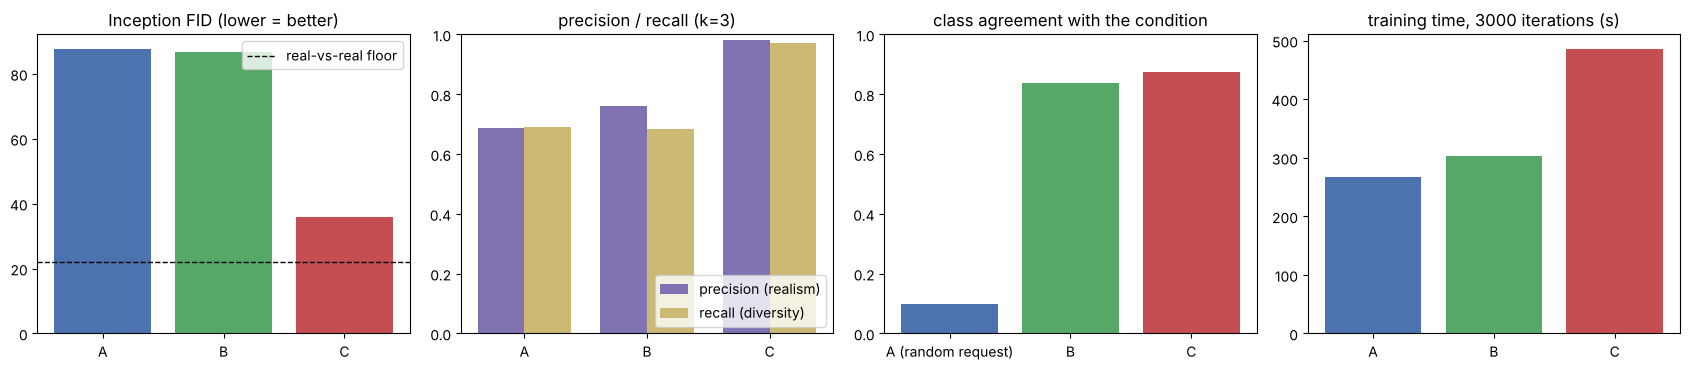

In [20]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
cols = ["#4C72B0", "#55A868", "#C44E52"]
ax[0].bar(range(3), [RES[k]["fid"] for k in order], color=cols)
ax[0].axhline(RES["real train images (floor)"]["fid"], color="k", ls="--", lw=1, label="real-vs-real floor")
ax[0].set(title="Inception FID (lower = better)", xticks=range(3), xticklabels=["A", "B", "C"])
ax[0].legend()
w = 0.38
ax[1].bar(np.arange(3) - w / 2, [RES[k]["precision"] for k in order], w, label="precision (realism)", color="#8172B2")
ax[1].bar(np.arange(3) + w / 2, [RES[k]["recall"] for k in order], w, label="recall (diversity)", color="#CCB974")
ax[1].set(title="precision / recall (k=3)", xticks=range(3), xticklabels=["A", "B", "C"], ylim=(0, 1))
ax[1].legend(loc="lower right")
ax[2].bar(range(3), [chance_a, RES["B: cGAN"]["cond_accuracy"], RES["C: pix2pix"]["cond_accuracy"]], color=cols)
ax[2].set(title="class agreement with the condition", xticks=range(3), xticklabels=["A (random request)", "B", "C"], ylim=(0, 1))
ax[3].bar(range(3), [COST[k]["seconds"] for k in order], color=cols)
ax[3].set(title="training time, %d iterations (s)" % CFG["iters"], xticks=range(3), xticklabels=["A", "B", "C"])
plt.tight_layout()
plt.show()

### Structured qualitative comparison (same grid, same criteria, for every approach)
One 10×10 grid per approach. A: random samples (nothing can be requested). B: one row per requested class. C: outputs for the first 100 held-out test edge maps, shown next to their ground truth in the next figure. Criteria applied identically: *realism* (sharp edges, plausible texture, no checkerboard), *diversity* (different shapes/styles, not near-duplicates), *correctness* (does the image match the condition, where there is one).

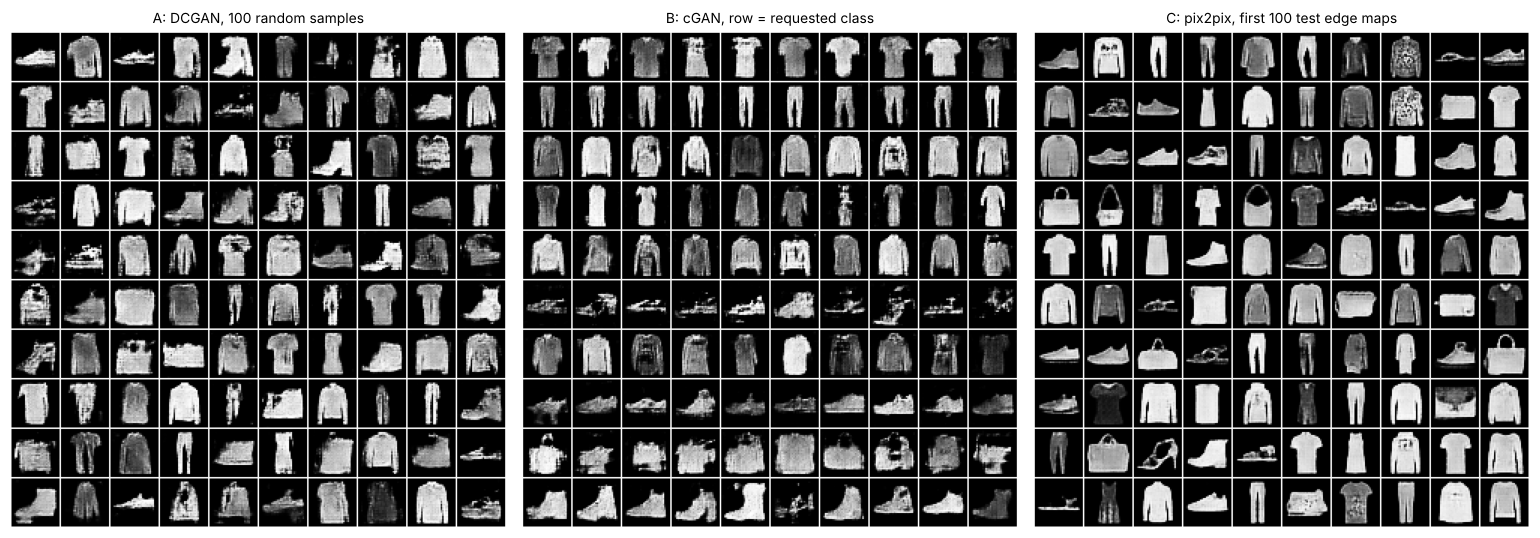

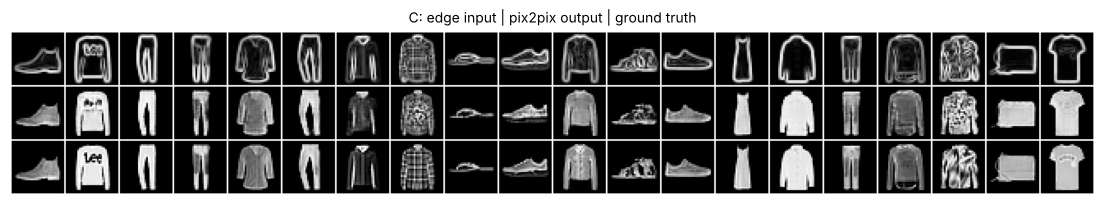

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.3))
show_grid(imgs_a[:100], 10, axes[0], "A: DCGAN, 100 random samples")
show_grid(G_B.eval()(torch.randn(100, CFG["nz"], 1, 1, device=DEVICE, generator=torch.Generator(device=DEVICE).manual_seed(SEED + 3)), (torch.arange(100, device=DEVICE) // 10)).detach().cpu(),
          10, axes[1], "B: cGAN, row = requested class")
G_B.train()
show_grid(imgs_c[:100], 10, axes[2], "C: pix2pix, first 100 test edge maps")
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(14, 2.5))
show_grid(torch.cat([E_TE[:20].cpu(), imgs_c[:20], gt[:20]]), 20, ax, "C: edge input | pix2pix output | ground truth")
plt.show()

# Part 6b — Seed replicates for A and B (training-run variance)
GAN training is unstable enough that one run is weak evidence (§3.2, and the brief's note on seeds). A and B are therefore **re-trained from scratch with a second seed** (different weight initialisation, data order and training noise), and evaluated with the cheap classifier-feature metrics only (Inception FID would cost ≈ 2.5 min per set here). The question this answers: *is the A-versus-B difference larger than the difference between two runs of the same approach?* C and its baseline are not replicated (compute), so conclusions about them are single-seed.

In [22]:
REPL: dict[str, dict] = {}
for tag, is_cond in [("A: DCGAN", False), ("B: cGAN", True)]:
    seed_all(SEED + 1)
    g_, d_ = DCGenerator(CFG["nz"], CFG["ng"], n_cls=10 if is_cond else 0).to(DEVICE), DCDiscriminator(CFG["ng"], n_cls=10 if is_cond else 0).to(DEVICE)
    h_ = train_gan(f"{tag} seed {SEED + 1}", g_, d_, CFG["iters"], seed=SEED + 1, verbose=False)
    im_, rq_ = sample_generator(g_, CFG["n_eval"], seed=SEED + 12)
    REPL[tag] = EVAL.score(im_, requested=rq_, with_fid=False)
    REPL[tag]["seconds"] = h_["seconds"]
    REPL[tag]["diag"] = diagnose(h_)
    REPL[tag]["ckpt_fd_cls"] = h_["ckpt_fd_cls"]
    print(f"{tag}: seed {SEED + 1} trained in {h_['seconds']:.0f} s")
    del g_, d_

rows = []
for tag in ["A: DCGAN", "B: cGAN"]:
    for sd, r in [(SEED, RES[tag]), (SEED + 1, REPL[tag])]:
        rows.append([tag, sd, f"{r['fd_cls']:.2f}", f"{r['precision']:.3f}", f"{r['recall']:.3f}", f"{r['class_entropy']:.3f}",
                     f"{r['cond_accuracy']:.3f}" if "cond_accuracy" in r else "-"])
table(rows, ["approach", "seed", "FD-cls (n=%d)" % n, "precision", "recall", "class entropy", "class agreement"])
within_a = abs(RES["A: DCGAN"]["fd_cls"] - REPL["A: DCGAN"]["fd_cls"])
within_b = abs(RES["B: cGAN"]["fd_cls"] - REPL["B: cGAN"]["fd_cls"])
gap = np.mean([RES["A: DCGAN"]["fd_cls"], REPL["A: DCGAN"]["fd_cls"]]) - np.mean([RES["B: cGAN"]["fd_cls"], REPL["B: cGAN"]["fd_cls"]])
print(f"\n[measured] seed-to-seed FD-cls difference: A {within_a:.2f}, B {within_b:.2f}; mean A - mean B = {gap:.2f}")
print("both replicate runs flagged by the Part 5 detector: " + ", ".join(
    f"{t}: collapse={REPL[t]['diag']['mode_collapse']} overpowered-D={REPL[t]['diag']['overpowered_d']} unstable={REPL[t]['diag']['unstable']}" for t in REPL))

A: DCGAN: seed 18 trained in 258 s


B: cGAN: seed 18 trained in 306 s
approach  seed  FD-cls (n=5000)  precision  recall  class entropy  class agreement
--------  ----  ---------------  ---------  ------  -------------  ---------------
A: DCGAN  17    38.47            0.689      0.690   0.990          -              
A: DCGAN  18    32.29            0.662      0.722   0.997          -              
B: cGAN   17    14.77            0.760      0.682   0.999          0.837          
B: cGAN   18    11.34            0.747      0.763   0.997          0.844          

[measured] seed-to-seed FD-cls difference: A 6.19, B 3.43; mean A - mean B = 22.32
both replicate runs flagged by the Part 5 detector: A: DCGAN: collapse=False overpowered-D=False unstable=False, B: cGAN: collapse=False overpowered-D=False unstable=False


# Part 7 — Findings, stability record and recommendation
*Every number below is copied from the tables printed above in this run (CPU, 3000 iterations per approach, Fashion-MNIST 32×32). Tags: `[measured]` = printed by this notebook; `[inference]` = my interpretation; `[hypothesis]` = plausible mechanism that this notebook did **not** test.*

## 7.1 What the measurements show
| | A: DCGAN | B: cGAN | C: pix2pix | C-baseline (L1 only) | real-vs-real floor |
|---|---|---|---|---|---|
| Inception FID, n = 1000 (lower is better) | 87.7 | 86.6 | 35.9 | 42.9 | 22.1 |
| FD-cls, n = 5000 (lower is better) | 38.5 (seed 18: 32.3) | 14.8 (seed 18: 11.3) | 2.77 | 4.64 | 0.48 |
| precision / recall | 0.689 / 0.690 | 0.760 / 0.682 | 0.981 / 0.971 | 0.982 / 0.918 | 0.900 / 0.895 |
| class agreement with the condition | none (0.10 for a random request) | 0.837 (seed 18: 0.844) | 0.875 | 0.863 | 0.900 (classifier on real images) |
| training time, 3000 iterations | 267 s | 302 s | 486 s | 237 s | — |
| generator parameters / MFLOPs per image | 0.37 M / 9.1 | 0.39 M / 9.1 | 1.54 M / 34.3 | — | — |

1. **Conditioning helped quality at this budget (A → B) `[measured]`.** B beats A on FD-cls in *both* seeds (14.8 and 11.3 versus 38.5 and 32.3). The A-versus-B gap (22.3 on average) is larger than the seed-to-seed difference inside either approach (6.2 for A, 3.4 for B), and B's precision is higher in both seeds (0.760 and 0.747 versus 0.689 and 0.662). Recall is not separable: B's two seeds differ from each other by more than B differs from A. `[hypothesis]` Feeding the label to both networks splits a ten-way mixture into ten easier conditional problems and lets the discriminator check class-consistency; this notebook did not test that mechanism.
2. **Inception FID did *not* separate A and B (87.7 versus 86.6) `[measured]`**, while FD-cls and precision did. I did not measure the sampling spread of Inception FID (≈ 2.5 min per set on this CPU) and cannot say whether this is small-sample noise (n = 1000 against 2048 dimensions) or insensitivity of Inception features to 32×32 grayscale clothing upsampled to 299 px. The brief's own §9.5 caution applies: with FID this noisy, the other metrics carry the A-versus-B comparison here.
3. **C is far ahead, but not like-for-like `[measured]`.** Its FID (35.9) is 14 above the real-vs-real floor and FD-cls of 2.77 is within about 2.3 of the floor of 0.48, with precision/recall near 0.98/0.97. `[inference]` That mostly reflects the task (an edge map contains the object's shape, which A and B must invent), not a better architecture.
4. **Controllability `[measured]`:** A offers none; its class mix at the end of training is 6 %–14 % per class instead of 10 %. B returns the requested class 83.7 % / 84.4 % of the time (two seeds) against a ceiling of 90.0 % for real images. The weakest requests are Shirt (0.564), Pullover (0.654) and Coat (0.668), the visually closest classes `[hypothesis: the classifier itself confuses them more on real images — not measured per class]`. The same-noise-different-class figure shows noise-driven style persisting along a row, e.g. one noise vector produces the same dark, patchy texture for several classes: the label controls *what*, the noise controls *how*.
5. **Does the adversarial term in pix2pix pay off? Yes for realism, no for pixel fidelity `[measured, single seed]`.** Against an identical U-Net trained with L1 only, adding the discriminator lowers FD-cls (2.77 versus 4.64) and Inception FID (35.9 versus 42.9) and raises recall (0.971 versus 0.918), but *worsens* every pixel metric (L1 0.0685 versus 0.0632; PSNR 23.2 versus 24.0 dB; SSIM 0.801 versus 0.809). In the qualitative figure the adversarial model reproduces fabric texture and prints, which the L1-only model smooths, but those textures are plausible rather than faithful to the ground truth, which is exactly what lower PSNR with better FID would predict. Caveat: on folds of n = 1000 the FD-cls means differ by 1.8 (4.60 ± 1.07 versus 6.42 ± 1.02) while a single fold fluctuates by about ±1.0; that sampling noise is small next to the gap, but it excludes training-run variance and C was trained once, so treat the sign as likely and the size as uncertain.
6. **Compute cost `[measured]`:** B costs about 13 % more training time than A and 5 % more parameters; C costs 1.8× A's training time and 3.8× the generator FLOPs per image (0.309 ms versus 0.129 ms per generated image on this CPU).

## 7.2 Stability record against §4's failure modes
| §4 failure mode | What was observed | How it was diagnosed |
|---|---|---|
| **Mode collapse (§4.1)** | Not observed in A or B, in either seed. After iteration 500 the class entropy of A's samples stayed ≥ 0.95 (minimum class share 3.8 %); B's stayed ≥ 0.99. Recall (0.68–0.76) is still below the real-data level (0.895) `[inference: partial coverage deficit after only ~3 epochs, not a collapse]`. | classifier class histogram per checkpoint; validated on a deliberately collapsed set (entropy 0.039, recall 0.128 while precision stayed 0.904) |
| **Instability (§4.2)** | Not observed. FD-cls fell at every checkpoint for A (229 → 40) and B (160 → 16); the largest consecutive ratio in the second half was 0.92 / 0.93. For C it flattened (2.97 → 3.20 → 3.09) without diverging. | FD-cls and D/G outputs at checkpoints; sample grids every 500 iterations |
| **Overpowered discriminator (§4.3)** | Transient only. In the first 200 iterations D(G(z)) averages 0.05 and shows a repeated rise-and-collapse pattern (ablation figure), then recovers to ≈ 0.31 by the end. | mean D(G(z)) over training |
| **Saturating generator loss (§3.4)** | **Reproduced on purpose.** With the original minimax loss the generator gradient norm is 0.041 versus 24.0 for the non-saturating loss in the first 200 iterations (about 600× smaller), D(G(z)) goes to 0.000, and after 1000 iterations FD-cls is 705 versus 137 with class entropy 0.80 versus 0.95. | ablation 1 (same seed, same budget) |
| **Discriminator updated 3× per step** | **No harm observed `[measured, single seed]`.** D(G(z)) was lower (0.090 versus 0.226 late) yet FD-cls after 1000 iterations was better (99.5 versus 137.4). This run gave D three times the updates, so it is not compute-matched and the result does not show that a stronger D is better in general; it only fails to confirm that an overpowered D hurts at this scale. | ablation 2 |

## 7.3 Recommendation: when each approach fits
* **Use A (vanilla / DCGAN, §5) when** you need a sampler of a dataset's overall distribution, no labels or inputs exist, and cost matters most: it was the cheapest (267 s, 9.1 MFLOPs per image). The price is that you cannot ask for anything (class mix drifts to 6–14 % per class) and it was the lowest quality here, by FD-cls and precision. It is the right *starting* template because the DCGAN guidelines trained stably out of the box in all four main GAN runs (A and B, two seeds each).
* **Use B (conditional GAN, §6) when** the user must be able to request an attribute that exists as a label. Here it cost 13 % more training time and gave better realism and 84 % correct requests. Limits: it needs labels for every attribute you want to control, correctness varied from 0.56 to 0.98 across classes, and it controls only what was labelled, not continuous properties such as pose.
* **Use C (pix2pix, §7) when** the output is determined by an input image and paired examples exist (sketch → image, restoration, style transfer within a paired domain). The input carries most of the information, so fidelity was highest by a wide margin, at the highest cost (1.8× A's training time, 3.8× the per-image FLOPs). Use the adversarial term when realistic *texture* matters; if the goal is pixel-accurate reconstruction, the L1-only model scored as well or better on L1, PSNR and SSIM. Where no paired data exist, §7.2's CycleGAN is the alternative; it was not tested here, so nothing in this notebook says how it would compare.
* **Rule of thumb that follows from these runs:** the more information you can put into the condition, the less the generator has to invent and the better the output looks for the same compute: A (none) → B (a label) → C (a full edge map). The comparison measures that ordering at this budget; it does not show that C's architecture is better than B's.

## 7.4 Limits of this study
* One dataset (Fashion-MNIST, 32×32, grayscale: easy and low-diversity), and a CPU-scale budget of 3000 iterations (≈ 3 epochs). Rankings at this budget need not hold after longer training, where the A-versus-B gap may shrink.
* A and B were run with two seeds; C, the L1-only baseline and both ablations with one. Conclusions that rest on them (items 5 and the D × 3 row) are tentative.
* Inception FID uses n = 1000 and its sampling spread was not measured; it disagreed with FD-cls on A versus B.
* FD-cls, precision/recall and class agreement come from a classifier *I* trained (90.0 % accuracy on real test images), so they measure similarity to Fashion-MNIST as that classifier sees it; the "ceiling" rows show how much headroom the instrument itself leaves.
* C's edge pairs are constructed with a Sobel filter, not collected pairs; C is conditioned on information A and B never see.
* The mode-collapse detector looks at class balance; collapse inside a class would show only through recall.

# Part 8 — Save results, submission checklist, README and references

In [23]:
def jsonable(o):
    if isinstance(o, dict):
        return {k: jsonable(v) for k, v in o.items() if not str(k).startswith("_")}
    if isinstance(o, (list, tuple)):
        return [jsonable(v) for v in o]
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    return o


torch.save({"G_A": G_A.state_dict(), "G_B": G_B.state_dict(), "G_C_pix2pix": G_C.state_dict(), "G_C_l1": G_L1.state_dict()}, OUT_DIR / "generators.pt")
slim = lambda h: {k: v for k, v in h.items() if k != "grids"}  # noqa: E731
(OUT_DIR / "results.json").write_text(json.dumps(jsonable(dict(
    config=CFG, seed=SEED, device=str(DEVICE), classifier_test_acc=CLF_TEST_ACC, metric_checks=CHECKS, results=RES, cost=COST,
    diagnostics=dict(A=DIAG_A, B=DIAG_B), seed_replicates=REPL, histories={"A": slim(HIST_A), "B": slim(HIST_B), "C": slim(HIST_C), "C_l1": slim(HIST_L1),
                                                     "abl_minimax": slim(HIST_SAT), "abl_d3": slim(HIST_OVER)})), indent=1))
print("saved", [p.name for p in OUT_DIR.iterdir()])

saved ['results.json', 'generators.pt']


### Submission checklist — computed from this run's own objects, not ticked by hand

In [24]:
def check(ok: bool, text: str) -> None:
    print(("[x] " if ok else "[ ] ") + text)


check(HIST_A["iters"] == CFG["iters"] and len(HIST_A["loss_d"]) == CFG["iters"], f"A (DCGAN) trained from scratch for {HIST_A['iters']} iterations and evaluated (FID {RES['A: DCGAN']['fid']:.1f})")
check(HIST_B["iters"] == CFG["iters"] and G_B.n_cls == 10, f"B (cGAN) trained from scratch and evaluated, class agreement {RES['B: cGAN']['cond_accuracy']:.3f} vs {chance_a:.3f} for A")
check(HIST_C["iters"] == CFG["iters"] and len(HIST_C["loss_d"]) == CFG["iters"], f"C (pix2pix) trained from scratch and evaluated (FID {RES['C: pix2pix']['fid']:.1f}, SSIM {RES['C: pix2pix']['ssim']:.3f})")
check(all("fid" in RES[k] for k in order), "FID computed for all three approaches with one protocol (same reference set, sample count and network)")
check(all(len(h["ckpt_iter"]) >= 2 for h in (HIST_A, HIST_B, HIST_C)), "sample grids saved at regular checkpoints for all three")
check(DIAG_A is not None and DIAG_B is not None and len(HIST_SAT["loss_g"]) > 0 and len(HIST_OVER["loss_g"]) > 0, "stability diagnostics + two deliberate failure-mode ablations (Part 5)")
check(all(k in RES for k in order) and all(k in COST for k in order), "comparison table and plot built from measured values (no placeholders)")
check((OUT_DIR / "results.json").exists() and (OUT_DIR / "generators.pt").exists(), "results.json and generator weights saved")
print("\nNot automated: the written recommendation (Part 7) must be read against the numbers above.")

[x] A (DCGAN) trained from scratch for 3000 iterations and evaluated (FID 87.7)
[x] B (cGAN) trained from scratch and evaluated, class agreement 0.837 vs 0.100 for A
[x] C (pix2pix) trained from scratch and evaluated (FID 35.9, SSIM 0.801)
[x] FID computed for all three approaches with one protocol (same reference set, sample count and network)
[x] sample grids saved at regular checkpoints for all three
[x] stability diagnostics + two deliberate failure-mode ablations (Part 5)
[x] comparison table and plot built from measured values (no placeholders)
[x] results.json and generator weights saved

Not automated: the written recommendation (Part 7) must be read against the numbers above.


## README — how to reproduce
1. Open the notebook in Colab (Runtime → T4 GPU recommended) or any machine with PyTorch ≥ 2.0. `pytorch-fid` is installed automatically.
2. *Runtime → Run all.* The first cell downloads Fashion-MNIST (≈ 31 MB) and the FID Inception weights (≈ 96 MB) from GitHub into `pp14_data/` and the torch hub cache.
3. Everything is seeded (`SEED = 17` for weights, data order and noise). Exact numbers can still differ across PyTorch versions and between CPU and GPU, so expect small differences in the last digits, not different conclusions; the notebook was run once, with a single seed, so run-to-run variance was **not** measured.
4. Budgets are set in the `CFG` dictionary (Part 0). On a T4 the default 3000 iterations per approach take a few minutes in total (on a 2-core CPU the whole notebook took the time printed at the end of the run). Set the environment variable `PP14_QUICK=1` for a ~1-minute smoke test of the whole pipeline with tiny budgets (numbers from that mode are meaningless).
5. Outputs: `pp14_outputs/results.json` (every number in the tables, plus training histories), `pp14_outputs/generators.pt` (the four trained generators).

## References
* Goodfellow et al., *Generative Adversarial Nets*, NeurIPS 2014 (minimax objective and the non-saturating alternative).
* Radford, Metz, Chintala, *Unsupervised Representation Learning with Deep Convolutional GANs*, ICLR 2016 (DCGAN guidelines).
* Mirza & Osindero, *Conditional Generative Adversarial Nets*, 2014 (cGAN).
* Isola, Zhu, Zhou, Efros, *Image-to-Image Translation with Conditional Adversarial Networks*, CVPR 2017 (pix2pix).
* Heusel et al., *GANs Trained by a Two Time-Scale Update Rule Converge to a Local Nash Equilibrium*, NeurIPS 2017 (FID).
* Kynkäänniemi et al., *Improved Precision and Recall Metric for Assessing Generative Models*, NeurIPS 2019.
* Xiao, Rasul, Vollgraf, *Fashion-MNIST*, 2017 (dataset, GitHub: zalandoresearch/fashion-mnist).
* Seitzer, *pytorch-fid* (FID implementation and ported Inception weights, GitHub: mseitzer/pytorch-fid).

I have not re-read these papers during this session; the descriptions above are from memory of their standard content and the Day 34 notes, and nothing in the notebook depends on a quoted figure from them.